In [6]:
# Quick test - basic imports
import sys
print(f"Python version: {sys.version}")
print("Basic import successful!")

Python version: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Basic import successful!


## 1. Import Required Libraries

In [7]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Scikit-learn utilities
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, RFE, mutual_info_classif
from sklearn.decomposition import PCA

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Advanced ML libraries (optional - install libomp via brew if needed)
try:
    import xgboost as xgb
    print("✓ XGBoost imported successfully")
except Exception as e:
    print(f"⚠ XGBoost not available. Run: brew install libomp")
    xgb = None

try:
    import lightgbm as lgb
    print("✓ LightGBM imported successfully")
except Exception as e:
    print(f"⚠ LightGBM not available: {str(e)[:50]}...")
    lgb = None

try:
    from catboost import CatBoostClassifier
    print("✓ CatBoost imported successfully")
except Exception as e:
    print(f"⚠ CatBoost not available: {str(e)[:50]}...")
    CatBoostClassifier = None

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    confusion_matrix, classification_report, matthews_corrcoef
)

# Handling imbalanced data
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

# Model interpretation
try:
    import shap
    print("✓ SHAP imported successfully")
except Exception as e:
    print(f"⚠ SHAP not available: {str(e)[:50]}...")
    shap = None

try:
    from lime import lime_tabular
    print("✓ LIME imported successfully")
except Exception as e:
    print(f"⚠ LIME not available: {str(e)[:50]}...")
    lime_tabular = None

# Model persistence
import joblib
import pickle

# Statistical analysis
from scipy import stats
from scipy.stats import zscore

# Date handling
from datetime import datetime

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("\n" + "="*60)
print("✓ Core libraries imported successfully!")
print("="*60)
print(f"Python version: {sys.version}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print("="*60)

✓ XGBoost imported successfully
✓ LightGBM imported successfully
⚠ CatBoost not available: No module named 'catboost'...
✓ SHAP imported successfully
⚠ LIME not available: No module named 'lime'...

✓ Core libraries imported successfully!
Python version: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Pandas version: 2.2.3
NumPy version: 1.26.4
Scikit-learn version: 1.5.1


## 2. Define File Paths and Configuration

In [8]:
# Base directory
BASE_DIR = Path('/Users/roya/Desktop/Thesis')
DATA_DIR = BASE_DIR / 'Data set'
OUTPUT_DIR = BASE_DIR / 'Thesis_Project' / 'ML'

# Data file paths
PART_B_FILE = DATA_DIR / 'Part B' / '2023' / 'MUP_PHY_R25_P05_V20_D23_Prov_Svc.csv'
PART_D_FILE = DATA_DIR / 'Medicare Part D Prescribers - by Provider and Drug' / '2023' / 'MUP_DPR_RY25_P04_V10_DY23_NPIBN.csv'
OIG_FILE = DATA_DIR / 'OIG.csv'

# Create output directories
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)
(OUTPUT_DIR / 'reports').mkdir(exist_ok=True)

print("✓ File paths configured")
print(f"Base Directory: {BASE_DIR}")
print(f"Data Directory: {DATA_DIR}")
print(f"Output Directory: {OUTPUT_DIR}")

✓ File paths configured
Base Directory: /Users/roya/Desktop/Thesis
Data Directory: /Users/roya/Desktop/Thesis/Data set
Output Directory: /Users/roya/Desktop/Thesis/Thesis_Project/ML


## 3. Data Loading & Initial Exploration

### 3.1 Load Medicare Part B Data

In [9]:
# Load Part B data (Provider Services)
print("Loading Medicare Part B 2023 data...")
part_b_df = pd.read_csv(PART_B_FILE, low_memory=False)

print(f"Part B Data Shape: {part_b_df.shape}")
print(f"\nMemory Usage: {part_b_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
part_b_df.head()

Loading Medicare Part B 2023 data...
Part B Data Shape: (9660647, 28)

Memory Usage: 11188.00 MB


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_State_FIPS,Rndrng_Prvdr_Zip5,Rndrng_Prvdr_RUCA,Rndrng_Prvdr_RUCA_Desc,Rndrng_Prvdr_Cntry,Rndrng_Prvdr_Type,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99221,Initial hospital care with straightforward or ...,N,F,12,12.0000,12,250.2267,89.0625,60.3125,54.6692
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99222,Initial hospital care with straightforward or ...,N,F,22,22.0000,22,318.5818,130.3127,99.3800,98.4295
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99231,Subsequent hospital care with straightforward ...,N,F,76,127.0000,127,95.7323,54.8202,43.5573,38.7487
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99232,Subsequent hospital care with moderate levelof...,N,F,180,341.0000,341,194.4415,86.8408,69.0864,61.8123
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99233,Subsequent hospital care with moderate levelof...,N,F,53,79.0000,79,251.4541,127.9152,100.9432,92.4091


### 3.2

In [10]:
# Filter to include only U.S. states and territories

us_states = ['AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 
             'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD', 
             'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 
             'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 
             'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY', 
             'DC', 'PR', 'VI', 'GU', 'AS', 'MP']

before_filter_b = len(part_b_df)
part_b_df = part_b_df[part_b_df['Rndrng_Prvdr_State_Abrvtn'].isin(us_states)]
after_filter_b = len(part_b_df)
removed_b = before_filter_b - after_filter_b

print(f"Part B: Removed {removed_b:,} non-U.S. records ({removed_b/before_filter_b*100:.2f}%)")
print(f"Part B: Remaining records: {after_filter_b:,}")
print(f"Part B Data Shape after filtering: {part_b_df.shape}")

Part B: Removed 1,696 non-U.S. records (0.02%)
Part B: Remaining records: 9,658,951
Part B Data Shape after filtering: (9658951, 28)


### 3.3

In [11]:
# Check if each provider has consistent location information
print("\n" + "="*80)
print("PROVIDER LOCATION CONSISTENCY CHECK - PART B")
print("="*80)

# Group by NPI and count unique values for State, Zipcode, and RUCA
provider_location_check_b = part_b_df.groupby('Rndrng_NPI').agg({
    'Rndrng_Prvdr_State_Abrvtn': 'nunique',
    'Rndrng_Prvdr_Zip5': 'nunique',
    'Rndrng_Prvdr_RUCA': 'nunique'
}).rename(columns={
    'Rndrng_Prvdr_State_Abrvtn': 'Unique_States',
    'Rndrng_Prvdr_Zip5': 'Unique_Zipcodes',
    'Rndrng_Prvdr_RUCA': 'Unique_RUCA'
})

# Count providers with single vs multiple values
total_providers = len(provider_location_check_b)
single_state = (provider_location_check_b['Unique_States'] == 1).sum()
multiple_states = (provider_location_check_b['Unique_States'] > 1).sum()

single_zip = (provider_location_check_b['Unique_Zipcodes'] == 1).sum()
multiple_zip = (provider_location_check_b['Unique_Zipcodes'] > 1).sum()

single_ruca = (provider_location_check_b['Unique_RUCA'] == 1).sum()
multiple_ruca = (provider_location_check_b['Unique_RUCA'] > 1).sum()

print(f"\nTotal unique providers: {total_providers:,}")
print(f"\n{'Field':<20} {'Single Value':<20} {'Multiple Values':<20}")
print("-" * 60)
print(f"{'State':<20} {single_state:,} ({single_state/total_providers*100:.2f}%)    {multiple_states:,} ({multiple_states/total_providers*100:.2f}%)")
print(f"{'Zipcode':<20} {single_zip:,} ({single_zip/total_providers*100:.2f}%)    {multiple_zip:,} ({multiple_zip/total_providers*100:.2f}%)")
print(f"{'RUCA Code':<20} {single_ruca:,} ({single_ruca/total_providers*100:.2f}%)    {multiple_ruca:,} ({multiple_ruca/total_providers*100:.2f}%)")

# Display Min and Max statistics for each unique column
print("\n" + "="*80)
print("MIN AND MAX STATISTICS FOR UNIQUE VALUES")
print("="*80)
print(f"\n{'Field':<20} {'Min':<15} {'Max':<15} {'Mean':<15}")
print("-" * 65)
print(f"{'Unique_States':<20} {provider_location_check_b['Unique_States'].min():<15} {provider_location_check_b['Unique_States'].max():<15} {provider_location_check_b['Unique_States'].mean():<15.2f}")
print(f"{'Unique_Zipcodes':<20} {provider_location_check_b['Unique_Zipcodes'].min():<15} {provider_location_check_b['Unique_Zipcodes'].max():<15} {provider_location_check_b['Unique_Zipcodes'].mean():<15.2f}")
print(f"{'Unique_RUCA':<20} {provider_location_check_b['Unique_RUCA'].min():<15} {provider_location_check_b['Unique_RUCA'].max():<15} {provider_location_check_b['Unique_RUCA'].mean():<15.2f}")

# Create detailed table for each provider
print("\n" + "="*80)
print("DETAILED PROVIDER LOCATION TABLE")
print("="*80)

# Add flag for consistency
provider_location_check_b['Has_Multiple_Locations'] = (
    (provider_location_check_b['Unique_States'] > 1) |
    (provider_location_check_b['Unique_Zipcodes'] > 1) |
    (provider_location_check_b['Unique_RUCA'] > 1)
)

# Display the table
print(f"\nShowing all {len(provider_location_check_b):,} providers:")
display(provider_location_check_b)

# Show providers with multiple locations
if multiple_states > 0 or multiple_zip > 0 or multiple_ruca > 0:
    print(f"\n{'='*80}")
    print("PROVIDERS WITH INCONSISTENT LOCATIONS")
    print("="*80)
    multi_location_providers = provider_location_check_b[
        provider_location_check_b['Has_Multiple_Locations']
    ]
    print(f"\nTotal providers with multiple locations: {len(multi_location_providers):,}")
    display(multi_location_providers)

print("="*80)


PROVIDER LOCATION CONSISTENCY CHECK - PART B

Total unique providers: 1,175,051

Field                Single Value         Multiple Values     
------------------------------------------------------------
State                1,175,051 (100.00%)    0 (0.00%)
Zipcode              1,175,051 (100.00%)    0 (0.00%)
RUCA Code            1,174,205 (99.93%)    0 (0.00%)

MIN AND MAX STATISTICS FOR UNIQUE VALUES

Field                Min             Max             Mean           
-----------------------------------------------------------------
Unique_States        1               1               1.00           
Unique_Zipcodes      1               1               1.00           
Unique_RUCA          0               1               1.00           

DETAILED PROVIDER LOCATION TABLE

Showing all 1,175,051 providers:


,Unique_States,Unique_Zipcodes,Unique_RUCA,Has_Multiple_Locations
Rndrng_NPI,,,,
1003000126,1,1,1,False
1003000134,1,1,1,False
1003000142,1,1,1,False
1003000423,1,1,1,False
1003000480,1,1,1,False
...,...,...,...,...
1992999478,1,1,1,False
1992999551,1,1,1,False
1992999775,1,1,1,False


In [12]:
print(part_b_df.columns)

Index(['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name',
       'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Ent_Cd',
       'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City',
       'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS',
       'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc',
       'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type',
       'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Cd', 'HCPCS_Desc',
       'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs',
       'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt',
       'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt'],
      dtype='object')


remove = ['Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'HCPCS_Desc', ]

keep = [ 'Rndrng_NPI', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_Zip5', Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Ent_Cd', '', 'Rndrng_Prvdr_Type', 'HCPCS_Cd', 'HCPCS_Drug_Ind', 'Place_Of_Srvc', 'Tot_Benes',	'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg',	'Avg_Mdcr_Alowd_Amt', 	'Avg_Mdcr_Pymt_Amt', 	'Avg_Mdcr_Stdzd_Amt'   ]

In [13]:
part_b_df['Rndrng_Prvdr_Ent_Cd'].unique()

array(['I', 'O'], dtype=object)

In [14]:
part_b_df['Rndrng_Prvdr_Cntry'].unique()

array(['US'], dtype=object)

In [15]:
part_b_df['HCPCS_Drug_Ind'].unique()

array(['N', 'Y'], dtype=object)

In [16]:
part_b_df['Rndrng_Prvdr_Crdntls'].unique()

array(['M.D.', 'MD', 'DO', ..., 'DO, PHD, MSC', 'MD MRO',
       'D.D.S., MPA, MAED'], dtype=object)

In [17]:
part_b_df['Rndrng_Prvdr_Mdcr_Prtcptg_Ind'].unique()

array(['Y', 'N'], dtype=object)

In [18]:
part_b_df['Rndrng_Prvdr_RUCA'].unique()

array([ 1. ,  4. ,  5. ,  2. ,  1.1,  3. ,  7. , 10. ,  8. ,  9. , 10.1,
        8.2, 99. , 10.2,  2.1,  4.1,  nan,  7.1,  6. ,  8.1,  7.2, 10.3,
        5.1])

### 3.4

In [19]:
provider_summary = part_b_df.groupby('Rndrng_NPI').agg({
    'Rndrng_Prvdr_Type': lambda x: list(x.unique()),
    'HCPCS_Cd': lambda x: list(x.unique()),
    'HCPCS_Drug_Ind': lambda x: list(x.unique())
}).reset_index()

provider_summary['Num_Unique_Provider_Types'] = provider_summary['Rndrng_Prvdr_Type'].apply(len)
provider_summary['Num_Unique_HCPCS_Codes'] = provider_summary['HCPCS_Cd'].apply(len)
provider_summary['Num_Unique_HCPCS_Drug_Ind'] = provider_summary['HCPCS_Drug_Ind'].apply(len)

provider_summary['Provider_Types'] = provider_summary['Rndrng_Prvdr_Type'].apply(lambda x: ', '.join(map(str, x)))
provider_summary['HCPCS_Codes'] = provider_summary['HCPCS_Cd'].apply(lambda x: ', '.join(map(str, x)))
provider_summary['HCPCS_Drug_Ind_List'] = provider_summary['HCPCS_Drug_Ind'].apply(lambda x: ', '.join(map(str, x)))

provider_summary_display = provider_summary[[
    'Rndrng_NPI',
    'Num_Unique_Provider_Types',
    'Num_Unique_HCPCS_Codes',
    'Num_Unique_HCPCS_Drug_Ind',
    'Provider_Types',
    'HCPCS_Codes',
    'HCPCS_Drug_Ind_List'
]]

print(f"\nTotal number of unique providers: {len(provider_summary_display)}")
print(f"\nFirst 20 providers:")
print(provider_summary_display.head(20).to_string(index=False))


print("SUMMARY STATISTICS")
print(f"Average provider types per provider: {provider_summary_display['Num_Unique_Provider_Types'].mean():.2f}")
print(f"Average HCPCS codes per provider: {provider_summary_display['Num_Unique_HCPCS_Codes'].mean():.2f}")
print(f"Average HCPCS Drug Ind per provider: {provider_summary_display['Num_Unique_HCPCS_Drug_Ind'].mean():.2f}")
print(f"Max provider types for a single provider: {provider_summary_display['Num_Unique_Provider_Types'].max()}")
print(f"Max HCPCS codes for a single provider: {provider_summary_display['Num_Unique_HCPCS_Codes'].max()}")
print(f"Max HCPCS Drug Ind for a single provider: {provider_summary_display['Num_Unique_HCPCS_Drug_Ind'].max()}")


provider_summary_display


Total number of unique providers: 1175051

First 20 providers:
 Rndrng_NPI  Num_Unique_Provider_Types  Num_Unique_HCPCS_Codes  Num_Unique_HCPCS_Drug_Ind                         Provider_Types                                                                                                                                                     HCPCS_Codes HCPCS_Drug_Ind_List
 1003000126                          1                       7                          1                            Hospitalist                                                                                                                 99221, 99222, 99231, 99232, 99233, 99238, 99239                   N
 1003000134                          1                      13                          1                              Pathology                                                                       88304, 88305, 88312, 88313, 88321, 88323, 88342, 88344, 88346, 88348, 88350, 88381, G0452                   N
 10030001

,Rndrng_NPI,Num_Unique_Provider_Types,Num_Unique_HCPCS_Codes,Num_Unique_HCPCS_Drug_Ind,Provider_Types,HCPCS_Codes,HCPCS_Drug_Ind_List
0,1003000126,1,7,1,Hospitalist,"99221, 99222, 99231, 99232, 99233, 99238, 99239",N
1,1003000134,1,13,1,Pathology,"88304, 88305, 88312, 88313, 88321, 88323, 8834...",N
2,1003000142,1,16,2,Anesthesiology,"27096, 62323, 64483, 64493, 64494, 64628, 6462...","N, Y"
3,1003000423,1,3,1,Obstetrics & Gynecology,"81002, G0101, Q0091",N
4,1003000480,1,4,1,General Surgery,"99202, 99203, 99212, 99213",N
...,...,...,...,...,...,...,...
1175046,1992999478,1,3,1,Licensed Clinical Social Worker,"90791, 90832, 90834",N
1175047,1992999551,1,12,2,Internal Medicine,"71046, 77067, 77080, 81003, 90662, 90677, 9300...","N, Y"
1175048,1992999775,1,6,1,Ambulatory Surgical Center,"27279, 62321, 62323, 63047, 64483, G0260",N
1175049,1992999825,1,6,1,Otolaryngology,"31575, 69210, 99203, 99204, 99213, 99214",N


In [20]:
part_b_df['Place_Of_Srvc'].unique()

array(['F', 'O'], dtype=object)

In [21]:
part_b_df['HCPCS_Drug_Ind'].unique()

array(['N', 'Y'], dtype=object)

In [22]:
# Basic information about Part B data
print("Part B Data Info:")
print("="*50)
part_b_df.info()

Part B Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 9658951 entries, 0 to 9660646
Data columns (total 28 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   Rndrng_NPI                     int64  
 1   Rndrng_Prvdr_Last_Org_Name     object 
 2   Rndrng_Prvdr_First_Name        object 
 3   Rndrng_Prvdr_MI                object 
 4   Rndrng_Prvdr_Crdntls           object 
 5   Rndrng_Prvdr_Ent_Cd            object 
 6   Rndrng_Prvdr_St1               object 
 7   Rndrng_Prvdr_St2               object 
 8   Rndrng_Prvdr_City              object 
 9   Rndrng_Prvdr_State_Abrvtn      object 
 10  Rndrng_Prvdr_State_FIPS        object 
 11  Rndrng_Prvdr_Zip5              object 
 12  Rndrng_Prvdr_RUCA              float64
 13  Rndrng_Prvdr_RUCA_Desc         object 
 14  Rndrng_Prvdr_Cntry             object 
 15  Rndrng_Prvdr_Type              object 
 16  Rndrng_Prvdr_Mdcr_Prtcptg_Ind  object 
 17  HCPCS_Cd                       ob

In [23]:
# Descriptive statistics for Part B
part_b_df.describe()

,Rndrng_NPI,Rndrng_Prvdr_RUCA,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
count,9658951.0000,9652446.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000,9658951.0000
mean,1499450669.5648,1.5640,85.3681,273.7899,136.4921,416.8325,106.1113,82.9943,82.3774
std,287708166.5262,3.3525,1354.2280,6809.9510,2185.7233,1433.3690,322.3450,257.0946,258.1591
min,1003000126.0000,1.0000,11.0000,5.5000,11.0000,0.0001,0.0000,0.0000,0.0000
25%,1245942010.0000,1.0000,17.0000,21.0000,20.0000,71.9900,26.9944,20.8466,19.9300
50%,1497946677.0000,1.0000,32.0000,43.0000,40.0000,175.0000,71.3776,53.1032,53.6263
75%,1740784544.5000,1.0000,72.0000,116.0000,103.0000,356.0000,122.1189,92.0193,92.3261
max,1992999874.0000,99.0000,870486.0000,5208424.0000,1778281.0000,99999.9900,52794.0407,42059.5177,42229.3294


### 3.2 Load Medicare Part D Data

### 3.2.1

In [24]:
# Load Part D data (Prescription Drugs)
print("Loading Medicare Part D 2023 data...")
part_d_df = pd.read_csv(PART_D_FILE, low_memory=False)

print(f"Part D Data Shape: {part_d_df.shape}")
print(f"\nMemory Usage: {part_d_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

part_d_df.head()

Loading Medicare Part D 2023 data...
Part D Data Shape: (26794878, 22)

Memory Usage: 18005.65 MB


,Prscrbr_NPI,Prscrbr_Last_Org_Name,Prscrbr_First_Name,Prscrbr_City,Prscrbr_State_Abrvtn,Prscrbr_State_FIPS,Prscrbr_Type,Prscrbr_Type_Src,Brnd_Name,Gnrc_Name,Tot_Clms,Tot_30day_Fills,Tot_Day_Suply,Tot_Drug_Cst,Tot_Benes,GE65_Sprsn_Flag,GE65_Tot_Clms,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Tot_Day_Suply,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes
0,1003000126,Enkeshafi,Ardalan,Bethesda,MD,24,Hospitalist,Claim-Specialty,Eliquis,Apixaban,13,15.3000,437,8828.7400,NaN,#,NaN,NaN,NaN,NaN,*,NaN
1,1003000126,Enkeshafi,Ardalan,Bethesda,MD,24,Hospitalist,Claim-Specialty,Prednisone,Prednisone,14,14.0000,153,54.9800,14.0000,#,NaN,NaN,NaN,NaN,#,NaN
2,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Acetaminophen-Codeine,Acetaminophen With Codeine,43,43.0000,1020,491.3800,12.0000,#,NaN,NaN,NaN,NaN,*,NaN
3,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Amitriptyline Hcl,Amitriptyline Hcl,35,35.0000,1050,471.0100,15.0000,#,NaN,NaN,NaN,NaN,*,NaN
4,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Baclofen,Baclofen,55,63.0000,1890,796.1000,23.0000,NaN,27.0000,29.0000,417.8600,870.0000,*,NaN


### 3.2.2

In [25]:

# Filter Part D data
before_filter_d = len(part_d_df)
part_d_df = part_d_df[part_d_df['Prscrbr_State_Abrvtn'].isin(us_states)]
after_filter_d = len(part_d_df)
removed_d = before_filter_d - after_filter_d

print(f"Part D: Removed {removed_d:,} non-U.S. records ({removed_d/before_filter_d*100:.2f}%)")
print(f"Part D: Remaining records: {after_filter_d:,}")
print(f"Part D Data Shape after filtering: {part_d_df.shape}")

Part D: Removed 3,037 non-U.S. records (0.01%)
Part D: Remaining records: 26,791,841
Part D Data Shape after filtering: (26791841, 22)


### 3.2.3

In [26]:
# Check if each provider has consistent location information
print("\n" + "="*80)
print("PROVIDER LOCATION CONSISTENCY CHECK - PART D")
print("="*80)

# Group by NPI and count unique values for State and Zipcode (Part D doesn't have RUCA)
provider_location_check_d = part_d_df.groupby('Prscrbr_NPI').agg({
    'Prscrbr_State_Abrvtn': 'nunique',
    'Prscrbr_State_FIPS': 'nunique'
}).rename(columns={
    'Prscrbr_State_Abrvtn': 'Unique_States',
    'Prscrbr_State_FIPS': 'Unique_State_FIPS'
})

# Count providers with single vs multiple values
total_providers_d = len(provider_location_check_d)
single_state_d = (provider_location_check_d['Unique_States'] == 1).sum()
multiple_states_d = (provider_location_check_d['Unique_States'] > 1).sum()

single_fips_d = (provider_location_check_d['Unique_State_FIPS'] == 1).sum()
multiple_fips_d = (provider_location_check_d['Unique_State_FIPS'] > 1).sum()

print(f"\nTotal unique prescribers: {total_providers_d:,}")
print(f"\n{'Field':<20} {'Single Value':<20} {'Multiple Values':<20}")
print("-" * 60)
print(f"{'State':<20} {single_state_d:,} ({single_state_d/total_providers_d*100:.2f}%)    {multiple_states_d:,} ({multiple_states_d/total_providers_d*100:.2f}%)")
print(f"{'State FIPS':<20} {single_fips_d:,} ({single_fips_d/total_providers_d*100:.2f}%)    {multiple_fips_d:,} ({multiple_fips_d/total_providers_d*100:.2f}%)")

# Display Min and Max statistics for each unique column
print("\n" + "="*80)
print("MIN AND MAX STATISTICS FOR UNIQUE VALUES")
print("="*80)
print(f"\n{'Field':<20} {'Min':<15} {'Max':<15} {'Mean':<15}")
print("-" * 65)
print(f"{'Unique_States':<20} {provider_location_check_d['Unique_States'].min():<15} {provider_location_check_d['Unique_States'].max():<15} {provider_location_check_d['Unique_States'].mean():<15.2f}")
print(f"{'Unique_State_FIPS':<20} {provider_location_check_d['Unique_State_FIPS'].min():<15} {provider_location_check_d['Unique_State_FIPS'].max():<15} {provider_location_check_d['Unique_State_FIPS'].mean():<15.2f}")

# Create detailed table for each provider
print("\n" + "="*80)
print("DETAILED PROVIDER LOCATION TABLE")
print("="*80)

# Add flag for consistency
provider_location_check_d['Has_Multiple_Locations'] = (
    (provider_location_check_d['Unique_States'] > 1) |
    (provider_location_check_d['Unique_State_FIPS'] > 1)
)

# Display the table
print(f"\nShowing all {len(provider_location_check_d):,} prescribers:")
display(provider_location_check_d)

# Show providers with multiple locations
if multiple_states_d > 0 or multiple_fips_d > 0:
    print(f"\n{'='*80}")
    print("PRESCRIBERS WITH INCONSISTENT LOCATIONS")
    print("="*80)
    multi_location_prescribers = provider_location_check_d[
        provider_location_check_d['Has_Multiple_Locations']
    ]
    print(f"\nTotal prescribers with multiple locations: {len(multi_location_prescribers):,}")
    display(multi_location_prescribers)

print("="*80)


PROVIDER LOCATION CONSISTENCY CHECK - PART D

Total unique prescribers: 1,103,872

Field                Single Value         Multiple Values     
------------------------------------------------------------
State                1,103,872 (100.00%)    0 (0.00%)
State FIPS           1,103,872 (100.00%)    0 (0.00%)

MIN AND MAX STATISTICS FOR UNIQUE VALUES

Field                Min             Max             Mean           
-----------------------------------------------------------------
Unique_States        1               1               1.00           
Unique_State_FIPS    1               1               1.00           

DETAILED PROVIDER LOCATION TABLE

Showing all 1,103,872 prescribers:


,Unique_States,Unique_State_FIPS,Has_Multiple_Locations
Prscrbr_NPI,,,
1003000126,1,1,False
1003000142,1,1,False
1003000167,1,1,False
1003000423,1,1,False
1003000480,1,1,False
...,...,...,...
1992999437,1,1,False
1992999551,1,1,False
1992999650,1,1,False


In [27]:
print(part_d_df.columns)

Index(['Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name',
       'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS',
       'Prscrbr_Type', 'Prscrbr_Type_Src', 'Brnd_Name', 'Gnrc_Name',
       'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst',
       'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills',
       'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag',
       'GE65_Tot_Benes'],
      dtype='object')


remove = ['Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_FIPS', 'Prscrbr_Type_Src',  'GE65_Sprsn_Flag', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Tot_Benes']

keep = ['Prscrbr_NPI', , 'Prscrbr_State_Abrvtn', 'Prscrbr_Type', 'Brnd_Name', 'Gnrc_Name','Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst','Tot_Benes']

Tot_30day_Fills': 'sum',  # How many monthly prescriptions the provider wrote

'Tot_Day_Suply': 'sum',  # Total number of days of medication given to patients

'Tot_Benes': 'sum',  # Number of different Medicare patients who received this drug from this provider(note: 0 means suppressed <11)
    
 how much money
'Tot_Drug_Cst': ['sum'],  # total money spent at pharmacies because of this provider’s prescriptions

### 3.2.4

In [28]:

# Aggregate data by provider (Prscrbr_NPI)
part_d_provider_summary = part_d_df.groupby('Prscrbr_NPI').agg({
    'Brnd_Name': lambda x: ', '.join(sorted(x.unique())),  
    'Gnrc_Name': lambda x: ', '.join(sorted(x.unique())),  
    'Tot_Clms': 'sum',          
    'Tot_30day_Fills': 'sum',    
    'Tot_Day_Suply': 'sum',      
    'Tot_Drug_Cst': 'sum',      
    'Tot_Benes': 'sum'          
}).reset_index()

# Add count columns for better insights
part_d_provider_summary['Num_Unique_Brand_Names'] = part_d_df.groupby('Prscrbr_NPI')['Brnd_Name'].nunique().values
part_d_provider_summary['Num_Unique_Generic_Names'] = part_d_df.groupby('Prscrbr_NPI')['Gnrc_Name'].nunique().values

# Reorder columns for better readability
part_d_provider_summary = part_d_provider_summary[[
    'Prscrbr_NPI',
    'Tot_Clms',
    'Tot_30day_Fills',
    'Tot_Day_Suply',
    'Tot_Drug_Cst',
    'Tot_Benes',
    'Num_Unique_Brand_Names',
    'Num_Unique_Generic_Names',
    'Brnd_Name',
    'Gnrc_Name'
]]

print(f"\nTotal unique providers: {len(part_d_provider_summary):,}")
print(f"\nSummary statistics:")
print(f"  Average claims per provider: {part_d_provider_summary['Tot_Clms'].mean():,.2f}")
print(f"  Average drug cost per provider: ${part_d_provider_summary['Tot_Drug_Cst'].mean():,.2f}")
print(f"  Average unique brand names per provider: {part_d_provider_summary['Num_Unique_Brand_Names'].mean():.2f}")
print(f"  Average unique generic names per provider: {part_d_provider_summary['Num_Unique_Generic_Names'].mean():.2f}")

print(f"\nFirst 10 providers:")

part_d_provider_summary.head(10)


Total unique providers: 1,103,872

Summary statistics:
  Average claims per provider: 1,262.32
  Average drug cost per provider: $192,660.38
  Average unique brand names per provider: 24.22
  Average unique generic names per provider: 23.10

First 10 providers:


,Prscrbr_NPI,Tot_Clms,Tot_30day_Fills,Tot_Day_Suply,Tot_Drug_Cst,Tot_Benes,Num_Unique_Brand_Names,Num_Unique_Generic_Names,Brnd_Name,Gnrc_Name
0,1003000126,27,29.3000,590,8883.7200,14.0000,2,2,"Eliquis, Prednisone","Apixaban, Prednisone"
1,1003000142,1769,1893.5000,53183,54440.2500,806.0000,21,21,"Acetaminophen-Codeine, Amitriptyline Hcl, Bacl...","Acetaminophen With Codeine, Amitriptyline Hcl,..."
2,1003000167,71,71.0000,328,190.0800,60.0000,2,2,"Amoxicillin, Dexamethasone","Amoxicillin, Dexamethasone"
3,1003000423,58,131.4000,3608,5670.2700,19.0000,2,2,"Clotrimazole-Betamethasone, Estradiol","Clotrimazole/Betamethasone Dip, Estradiol"
4,1003000480,28,30.1000,583,409.7000,12.0000,2,2,"Omeprazole, Oxycodone Hcl","Omeprazole, Oxycodone Hcl"
5,1003000530,6467,13395.3000,394426,344845.1200,1325.0000,115,108,"Advair Diskus, Albuterol Sulfate Hfa, Alendron...","Albuterol Sulfate, Alendronate Sodium, Alfuzos..."
6,1003000597,1839,3227.7000,82400,272895.9800,853.0000,18,17,"Amoxicillin-Clavulanate Potass, Cephalexin, Ci...","Amoxicillin/Potassium Clav, Cephalexin, Ciprof..."
7,1003000720,302,306.8000,3352,4308.4500,293.0000,11,11,"Albuterol Sulfate Hfa, Amoxicillin-Clavulanate...","Albuterol Sulfate, Amoxicillin/Potassium Clav,..."
8,1003000738,30,30.0000,636,203.7000,26.0000,2,2,"Meloxicam, Methylprednisolone","Meloxicam, Methylprednisolone"
9,1003000746,83,83.0000,199,25135.2500,80.0000,2,2,"Abrysvo, Shingrix","Rsv Vacc, Pref A And Pref B/Pf, Varicella-Zost..."


### 3.2.5

In [29]:
print("PROVIDER SUMMARY TABLE - PART D")

provider_summary_d = part_d_df.groupby('Prscrbr_NPI').agg({
    'Prscrbr_Type': lambda x: list(x.unique()), # Unique = Duplicate, lambda = summerize the function
    'Brnd_Name': lambda x: list(x.unique()),
    'Gnrc_Name': lambda x: list(x.unique())
}).reset_index() # groupby moves NPI to the left margin, brings it back into the table 

# In this part of the code I create a new column that counts the number of unique items stored inside each row’s list/set column.
provider_summary_d['Num_Unique_Provider_Types'] = provider_summary_d['Prscrbr_Type'].apply(len)
provider_summary_d['Num_Unique_Brnd_Names'] = provider_summary_d['Brnd_Name'].apply(len)
provider_summary_d['Num_Unique_Gnrc_Names'] = provider_summary_d['Gnrc_Name'].apply(len)

# Convert lists to strings for better display
provider_summary_d['Provider_Types'] = provider_summary_d['Prscrbr_Type'].apply(lambda x: ', '.join(map(str, x)))
provider_summary_d['Brand_Names'] = provider_summary_d['Brnd_Name'].apply(lambda x: ', '.join(map(str, x)))
provider_summary_d['Generic_Names'] = provider_summary_d['Gnrc_Name'].apply(lambda x: ', '.join(map(str, x)))

# Create final display table with reordered columns
provider_summary_d_display = provider_summary_d[[
    'Prscrbr_NPI',
    'Num_Unique_Provider_Types',
    'Num_Unique_Brnd_Names',
    'Num_Unique_Gnrc_Names',
    'Provider_Types',
    'Brand_Names',
    'Generic_Names'
]]

print(f"\nTotal number of unique providers: {len(provider_summary_d_display)}")
print(f"\nFirst 20 providers:")
print(provider_summary_d_display.head(20).to_string(index=False))

print("SUMMARY STATISTICS - PART D")
print(f"Average provider types per provider: {provider_summary_d_display['Num_Unique_Provider_Types'].mean():.2f}")
print(f"Average brand names per provider: {provider_summary_d_display['Num_Unique_Brnd_Names'].mean():.2f}")
print(f"Average generic names per provider: {provider_summary_d_display['Num_Unique_Gnrc_Names'].mean():.2f}")
print(f"Max provider types for a single provider: {provider_summary_d_display['Num_Unique_Provider_Types'].max()}")
print(f"Max brand names for a single provider: {provider_summary_d_display['Num_Unique_Brnd_Names'].max()}")
print(f"Max generic names for a single provider: {provider_summary_d_display['Num_Unique_Gnrc_Names'].max()}")

# Show the full table (optional - can be commented out for large datasets)
provider_summary_d_display

PROVIDER SUMMARY TABLE - PART D

Total number of unique providers: 1103872

First 20 providers:
 Prscrbr_NPI  Num_Unique_Provider_Types  Num_Unique_Brnd_Names  Num_Unique_Gnrc_Names                       Provider_Types                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

,Prscrbr_NPI,Num_Unique_Provider_Types,Num_Unique_Brnd_Names,Num_Unique_Gnrc_Names,Provider_Types,Brand_Names,Generic_Names
0,1003000126,1,2,2,Hospitalist,"Eliquis, Prednisone","Apixaban, Prednisone"
1,1003000142,1,21,21,Anesthesiology,"Acetaminophen-Codeine, Amitriptyline Hcl, Bacl...","Acetaminophen With Codeine, Amitriptyline Hcl,..."
2,1003000167,1,2,2,Dentist,"Amoxicillin, Dexamethasone","Amoxicillin, Dexamethasone"
3,1003000423,1,2,2,Obstetrics & Gynecology,"Clotrimazole-Betamethasone, Estradiol","Clotrimazole/Betamethasone Dip, Estradiol"
4,1003000480,1,2,2,General Surgery,"Omeprazole, Oxycodone Hcl","Omeprazole, Oxycodone Hcl"
...,...,...,...,...,...,...,...
1103867,1992999437,1,4,4,Emergency Medicine,"Diclofenac Sodium, Famotidine, Methylprednisol...","Diclofenac Sodium, Famotidine, Methylprednisol..."
1103868,1992999551,1,82,78,Internal Medicine,"Advair Diskus, Albuterol Sulfate Hfa, Alendron...","Fluticasone Propion/Salmeterol, Albuterol Sulf..."
1103869,1992999650,1,3,3,Dentist,"Amoxicillin, Chlorhexidine Gluconate, Sodium F...","Amoxicillin, Chlorhexidine Gluconate, Sodium F..."
1103870,1992999825,1,9,9,Otolaryngology,"Amoxicillin-Clavulanate Potass, Cephalexin, Ci...","Amoxicillin/Potassium Clav, Cephalexin, Ciprof..."


In [30]:
part_d_df['Prscrbr_State_Abrvtn'].unique()

array(['MD', 'OH', 'NV', 'CO', 'PA', 'OK', 'FL', 'TX', 'NM', 'KY', 'SC',
       'CT', 'CA', 'NY', 'NJ', 'MA', 'MS', 'VA', 'OR', 'ID', 'WA', 'NH',
       'MN', 'DC', 'GA', 'NC', 'AZ', 'TN', 'IA', 'ND', 'NE', 'IL', 'IN',
       'AL', 'AR', 'HI', 'RI', 'LA', 'WI', 'KS', 'MI', 'WV', 'VT', 'UT',
       'PR', 'MO', 'DE', 'MT', 'ME', 'AK', 'SD', 'WY', 'GU', 'VI', 'MP',
       'AS'], dtype=object)

In [31]:
part_d_df['Prscrbr_Type_Src'].unique()

array(['Claim-Specialty', 'NPPES-Specialty', 'NPPES-Taxonomy'],
      dtype=object)

In [32]:
# Basic information about Part D data
print("Part D Data Info:")
print("="*50)
part_d_df.info()

Part D Data Info:
<class 'pandas.core.frame.DataFrame'>
Index: 26791841 entries, 0 to 26794877
Data columns (total 22 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Prscrbr_NPI            int64  
 1   Prscrbr_Last_Org_Name  object 
 2   Prscrbr_First_Name     object 
 3   Prscrbr_City           object 
 4   Prscrbr_State_Abrvtn   object 
 5   Prscrbr_State_FIPS     object 
 6   Prscrbr_Type           object 
 7   Prscrbr_Type_Src       object 
 8   Brnd_Name              object 
 9   Gnrc_Name              object 
 10  Tot_Clms               int64  
 11  Tot_30day_Fills        float64
 12  Tot_Day_Suply          int64  
 13  Tot_Drug_Cst           float64
 14  Tot_Benes              float64
 15  GE65_Sprsn_Flag        object 
 16  GE65_Tot_Clms          float64
 17  GE65_Tot_30day_Fills   float64
 18  GE65_Tot_Drug_Cst      float64
 19  GE65_Tot_Day_Suply     float64
 20  GE65_Bene_Sprsn_Flag   object 
 21  GE65_Tot_Benes         float64
dtypes: 

### 3.3 Load OIG Exclusion List

In [33]:
# Load OIG exclusion list
print("Loading OIG Exclusion List...")
oig_df = pd.read_csv(OIG_FILE, low_memory=False)

print(f"OIG Data Shape: {oig_df.shape}")
print(f"\nMemory Usage: {oig_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

oig_df.head()

Loading OIG Exclusion List...
OIG Data Shape: (82100, 18)

Memory Usage: 51.98 MB


,LASTNAME,FIRSTNAME,MIDNAME,BUSNAME,GENERAL,SPECIALTY,UPIN,NPI,DOB,ADDRESS,CITY,STATE,ZIP,EXCLTYPE,EXCLDATE,REINDATE,WAIVERDATE,WVRSTATE
0,NaN,NaN,NaN,"#1 MARKETING SERVICE, INC",OTHER BUSINESS,SOBER HOME,NaN,0,NaN,239 BRIGHTON BEACH AVENUE,BROOKLYN,NY,11235,1128a1,20200319,0,0,NaN
1,NaN,NaN,NaN,"1 BEST CARE, INC",OTHER BUSINESS,HOME HEALTH AGENCY,NaN,0,NaN,"2161 UNIVERSITY AVENUE W, STE",SAINT PAUL,MN,55114,1128b5,20230518,0,0,NaN
2,NaN,NaN,NaN,101 FIRST CARE PHARMACY INC,OTHER BUSINESS,PHARMACY,NaN,1972902351,NaN,"C/O 609 W 191ST STREET, APT D",NEW YORK,NY,10040,1128b8,20220320,0,0,NaN
3,NaN,NaN,NaN,14 LAWRENCE AVE PHARMACY,PHARMACY,NaN,NaN,0,NaN,14 LAWRENCE AVENUE,SMITHTOWN,NY,11787,1128a1,19880830,0,0,NaN
4,NaN,NaN,NaN,143 MEDICAL EQUIPMENT CO,DME COMPANY,DME - OXYGEN,NaN,0,NaN,701 NW 36 AVENUE,MIAMI,FL,33125,1128b7,19970620,0,0,NaN


In [34]:
print(oig_df.columns)

Index(['LASTNAME', 'FIRSTNAME', 'MIDNAME', 'BUSNAME', 'GENERAL', 'SPECIALTY',
       'UPIN', 'NPI', 'DOB', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'EXCLTYPE',
       'EXCLDATE', 'REINDATE', 'WAIVERDATE', 'WVRSTATE'],
      dtype='object')


In [35]:
# Examine OIG data structure
print("OIG Data Info:")
oig_df.info()

print("Unique values in key columns:")
print(f"Unique Last Names: {oig_df['LASTNAME'].nunique() if 'LASTNAME' in oig_df.columns else 'N/A'}")
print(f"Unique States: {oig_df['STATE'].nunique() if 'STATE' in oig_df.columns else 'N/A'}")

OIG Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82100 entries, 0 to 82099
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   LASTNAME    78730 non-null  object 
 1   FIRSTNAME   78729 non-null  object 
 2   MIDNAME     58025 non-null  object 
 3   BUSNAME     3368 non-null   object 
 4   GENERAL     82100 non-null  object 
 5   SPECIALTY   78014 non-null  object 
 6   UPIN        5967 non-null   object 
 7   NPI         82100 non-null  int64  
 8   DOB         77868 non-null  float64
 9   ADDRESS     82096 non-null  object 
 10  CITY        82100 non-null  object 
 11  STATE       82100 non-null  object 
 12  ZIP         82100 non-null  int64  
 13  EXCLTYPE    82100 non-null  object 
 14  EXCLDATE    82100 non-null  int64  
 15  REINDATE    82100 non-null  int64  
 16  WAIVERDATE  82100 non-null  int64  
 17  WVRSTATE    5 non-null      object 
dtypes: float64(1), int64(5), object(12)
memory usage: 1

## 4. Data Quality Assessment

### 4.1 Missing Values Analysis

In [36]:
def analyze_missing_values(df, df_name):
    print(f"Missing Values Analysis: {df_name}")

    missing_values = ['', ' ', '  ', 'nan', 'NaN', 'NA', 'N/A', 'null', 'NULL', 'None', 'none', '<NA>']
    df_temp = df.replace(missing_values, pd.NA)
    
    missing_count = df_temp.isnull().sum()
    missing_percent = (missing_count / len(df_temp)) * 100
    
    missing_df = pd.DataFrame({
        'Column': df_temp.columns,
        'Missing_Count': missing_count.values,
        'Missing_Percent': missing_percent.values
    })
    
    missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(
        'Missing_Percent', ascending=False
    ).reset_index(drop=True)
    
    if len(missing_df) == 0:
        print("✓ No missing values found!")
    else:
        print(f"\nColumns with missing values: {len(missing_df)}")
        print(missing_df)
        
        if len(missing_df) <= 20:
            fig = px.bar(
                missing_df,
                x='Column',
                y='Missing_Percent',
                title=f'Missing Values in {df_name}',
                labels={'Missing_Percent': 'Missing %'},
                text='Missing_Percent'
            )
            fig.update_traces(texttemplate='%{text:.2f}%', textposition='outside')
            fig.update_layout(xaxis_tickangle=-45, height=500)
            fig.show()
    
    return missing_df

missing_part_b = analyze_missing_values(part_b_df, 'Medicare Part B 2023')
missing_part_d = analyze_missing_values(part_d_df, 'Medicare Part D 2023')
missing_oig = analyze_missing_values(oig_df, 'OIG Exclusion List')

Missing Values Analysis: Medicare Part B 2023

Columns with missing values: 6
                    Column  Missing_Count  Missing_Percent
0         Rndrng_Prvdr_St2        7352762          76.1238
1          Rndrng_Prvdr_MI        3388472          35.0812
2     Rndrng_Prvdr_Crdntls        1080413          11.1856
3  Rndrng_Prvdr_First_Name         537099           5.5606
4        Rndrng_Prvdr_RUCA           6505           0.0673
5   Rndrng_Prvdr_RUCA_Desc           6505           0.0673


Missing Values Analysis: Medicare Part D 2023

Columns with missing values: 10
                 Column  Missing_Count  Missing_Percent
0        GE65_Tot_Benes       23698095          88.4527
1             Tot_Benes       14755931          55.0762
2       GE65_Sprsn_Flag       14722583          54.9517
3         GE65_Tot_Clms       12069258          45.0483
4  GE65_Tot_30day_Fills       12069258          45.0483
5     GE65_Tot_Drug_Cst       12069258          45.0483
6    GE65_Tot_Day_Suply       12069258          45.0483
7  GE65_Bene_Sprsn_Flag        3093746          11.5473
8    Prscrbr_First_Name              9           0.0000
9          Prscrbr_Type              2           0.0000


Missing Values Analysis: OIG Exclusion List

Columns with missing values: 9
      Column  Missing_Count  Missing_Percent
0   WVRSTATE          82095          99.9939
1    BUSNAME          78732          95.8977
2       UPIN          76133          92.7320
3    MIDNAME          24075          29.3240
4        DOB           4232           5.1547
5  SPECIALTY           4086           4.9769
6  FIRSTNAME           3371           4.1060
7   LASTNAME           3370           4.1048
8    ADDRESS              4           0.0049


### 4.2 Duplicate Records Check

In [37]:
def check_duplicates(df, df_name):
    print(f"\nDuplicate Analysis: {df_name}")

    full_duplicates = df.duplicated().sum()
    print(f"Full duplicate rows: {full_duplicates} ({full_duplicates/len(df)*100:.2f}%)")
    
    return full_duplicates

dup_part_b = check_duplicates(part_b_df, 'Part B')
dup_part_d = check_duplicates(part_d_df, 'Part D')
dup_oig = check_duplicates(oig_df, 'OIG')


Duplicate Analysis: Part B
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: Part D
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: OIG
Full duplicate rows: 25 (0.03%)


## 5. Data Preprocessing & Cleaning


In [38]:
def basic_data_cleaning(df, df_name):
    
    df_clean = df.copy()
    initial_rows = len(df_clean)
    
    # Step 1: Remove exact duplicates
    before_dedup = len(df_clean)
    df_clean = df_clean.drop_duplicates()
    after_dedup = len(df_clean)
    removed_dups = before_dedup - after_dedup
    print(f"1. Removed duplicates: {removed_dups:,} rows")
    
    # Step 2: Standardize NPI format (if NPI column exists)
    npi_cols = [col for col in df_clean.columns if 'NPI' in col.upper()]
    for npi_col in npi_cols:
        if df_clean[npi_col].dtype == 'object':
            # Convert to string, remove whitespace
            df_clean[npi_col] = df_clean[npi_col].astype(str).str.strip()
            # Remove non-numeric NPIs (keep NaN as-is)
            valid_npi = df_clean[npi_col].str.isnumeric() | df_clean[npi_col].isna()
            invalid_count = (~valid_npi).sum()
            if invalid_count > 0:
                df_clean = df_clean[valid_npi]
                print(f"2. Removed invalid NPIs in {npi_col}: {invalid_count:,} rows")
    
    # Step 3: Remove rows with completely missing data (all NaN)
    all_nan_rows = df_clean.isnull().all(axis=1).sum()
    if all_nan_rows > 0:
        df_clean = df_clean.dropna(how='all')
        print(f"3. Removed completely empty rows: {all_nan_rows:,}")
    
    final_rows = len(df_clean)
    total_removed = initial_rows - final_rows
    missing_count = df_clean.isnull().sum().sum()
    
    print(f"\nCLEANING SUMMARY:")
    print(f"  Initial rows:     {initial_rows:,}")
    print(f"  Final rows:       {final_rows:,}")
    print(f"  Rows removed:     {total_removed:,} ({total_removed/initial_rows*100:.2f}%)")
    print(f"  Missing values:   {missing_count:,} (PRESERVED for post-aggregation imputation)")
    print("="*80)
    print()
    
    return df_clean


In [39]:
print("Applying basic data cleaning (no imputation yet)...")
print()

part_b_clean = basic_data_cleaning(part_b_df, "Part B - Provider Services")
part_d_clean = basic_data_cleaning(part_d_df, "Part D - Prescription Drugs")
oig_clean = basic_data_cleaning(oig_df, "OIG - Exclusion List")


print("✓ Basic cleaning complete! Missing values preserved for post-aggregation imputation.")


Applying basic data cleaning (no imputation yet)...

1. Removed duplicates: 0 rows

CLEANING SUMMARY:
  Initial rows:     9,658,951
  Final rows:       9,658,951
  Rows removed:     0 (0.00%)
  Missing values:   12,371,756 (PRESERVED for post-aggregation imputation)

1. Removed duplicates: 0 rows

CLEANING SUMMARY:
  Initial rows:     26,791,841
  Final rows:       26,791,841
  Rows removed:     0 (0.00%)
  Missing values:   104,547,398 (PRESERVED for post-aggregation imputation)

1. Removed duplicates: 25 rows

CLEANING SUMMARY:
  Initial rows:     82,100
  Final rows:       82,075
  Rows removed:     25 (0.03%)
  Missing values:   276,007 (PRESERVED for post-aggregation imputation)

✓ Basic cleaning complete! Missing values preserved for post-aggregation imputation.


## 6. Provider-Level Aggregation


### 6.1 Create Provider-Level Aggregations - Part B

We'll aggregate data at the provider (NPI) level to create features.

In [40]:
print("Creating provider-level aggregations from Part B data...")

# Aggregate Part B data by provider (NPI)
part_b_agg = part_b_clean.groupby('Rndrng_NPI').agg({
    # Provider information (first value since it should be same for each NPI)
    'Rndrng_Prvdr_Last_Org_Name': 'first',
    'Rndrng_Prvdr_First_Name': 'first',
    'Rndrng_Prvdr_State_Abrvtn': 'first',
    'Rndrng_Prvdr_Zip5': 'first',
    'Rndrng_Prvdr_Type': 'first', # Derived from the provider specialty code reported on the claim. For providers that reported more than one specialty code on their claims, this is the specialty code associated with the largest number of services.
    'Rndrng_Prvdr_Ent_Cd': 'first',  # Entity code (Individual vs Organization)
    'Rndrng_Prvdr_RUCA': 'first',  # Rural-Urban Commuting Area code
    
    # Volume metrics - Total counts
    'Tot_Benes': 'sum',  # Number of distinct Medicare beneficiaries receiving thservice for each Rndrng_NPI, HCPCS_Cd, and Place_Of_Srvc.
    'Tot_Srvcs': 'sum',  
    'Tot_Bene_Day_Srvcs': 'sum', 
    
    # Financial metrics - Average amounts per service
    'Avg_Sbmtd_Chrg': ['mean', 'max'],  # Average of the charges that the provider submitted for theservice.
    'Avg_Mdcr_Alowd_Amt': ['mean', 'max'],  # Average of the Medicare allowed amount for the service. 
    'Avg_Mdcr_Pymt_Amt': ['mean', 'sum'], # Average amount that Medicare paid after deductible and coisurance amounts have been deducted for the line item sevice.
    'Avg_Mdcr_Stdzd_Amt': 'mean', # Average amount that Medicare paid after beneficiary deductible and coinsurance amounts have been deducted for the line item service and after standardization of the Medicare payment has been applied. 
    
    # Service diversity and complexity
    'HCPCS_Cd': 'nunique',  # Number of unique procedure/service codes - measures provider's service diversity
    'HCPCS_Drug_Ind': 'nunique',  # Number of unique drug indicators (drug vs non-drug services)
    'Place_Of_Srvc': 'nunique',  # Number of unique service places facility and non-facility
}).reset_index()

# Flatten multi-level columns from aggregation
part_b_agg.columns = ['_'.join(col).strip('_') if isinstance(col, tuple) else col for col in part_b_agg.columns.values]

# Rename columns for clarity
column_mapping = {
    'Rndrng_NPI': 'NPI',
    'Rndrng_Prvdr_Last_Org_Name_first': 'Provider_Name',
    'Rndrng_Prvdr_First_Name_first': 'Provider_FirstName',
    'Rndrng_Prvdr_State_Abrvtn_first': 'State',
    'Rndrng_Prvdr_Zip5_first': 'Zipcode',
    'Rndrng_Prvdr_Type_first': 'Provider_Type',
    'Rndrng_Prvdr_Ent_Cd_first': 'Entity_Code',
    'Rndrng_Prvdr_RUCA_first': 'RUCA_Code',
    'Tot_Benes_sum': 'Total_Beneficiaries_B',
    'Tot_Srvcs_sum': 'Total_Services_B',
    'Tot_Bene_Day_Srvcs_sum': 'Total_BeneDay_Services_B',
    'Avg_Sbmtd_Chrg_mean': 'Avg_Submitted_Charge_B',
    'Avg_Sbmtd_Chrg_max': 'Max_Submitted_Charge_B',
    'Avg_Mdcr_Alowd_Amt_mean': 'Avg_Medicare_Allowed_B',
    'Avg_Mdcr_Alowd_Amt_max': 'Max_Medicare_Allowed_B',
    'Avg_Mdcr_Pymt_Amt_mean': 'Avg_Medicare_Payment_B',
    'Avg_Mdcr_Pymt_Amt_sum': 'Total_Medicare_Payment_B',
    'Avg_Mdcr_Stdzd_Amt_mean': 'Avg_Medicare_Standardized_B',
    'HCPCS_Cd_nunique': 'Unique_Procedures_B',
    'HCPCS_Drug_Ind_nunique': 'Service_Type_Diversity_B', # 1= show one service ( Drug or Non- Drug), BOTH drug services and medical services (value would be 2)
    'Place_Of_Srvc_nunique': 'Unique_Service_Places_B'
}
part_b_agg.rename(columns=column_mapping, inplace=True)

print(f"✓ Part B aggregated to {len(part_b_agg):,} unique providers")
print(f"  Columns: {part_b_agg.shape[1]}")
print(f"  Features: {part_b_agg.shape[1] - 7} numeric + 7 descriptive")
print(f"  Key diversity metrics: Unique_Procedures_B (HCPCS codes), Service_Type_Diversity_B (Drug/Medical), Unique_Service_Places_B")
print("="*80)
part_b_agg.head()

Creating provider-level aggregations from Part B data...
✓ Part B aggregated to 1,175,051 unique providers
  Columns: 21
  Features: 14 numeric + 7 descriptive
  Key diversity metrics: Unique_Procedures_B (HCPCS codes), Service_Type_Diversity_B (Drug/Medical), Unique_Service_Places_B


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Service_Type_Diversity_B,Unique_Service_Places_B
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,556,802.0000,802,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7,1,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,2912,4774.0000,3296,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13,1,1
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,804,1257.0000,1113,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16,2,2
3,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,75,75.0000,75,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3,1,1
4,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,1.0000,59,60.0000,60,233.0000,325.0000,58.5837,83.3891,44.7490,178.9962,43.5455,4,1,1


### 6.2 Create Provider-Level Aggregations - Part D

In [41]:
print("\nCreating provider-level aggregations from Part D data...")

# Aggregate Part D data by prescriber (NPI)
part_d_agg = part_d_clean.groupby('Prscrbr_NPI').agg({
    'Prscrbr_Last_Org_Name': 'first',
    'Prscrbr_First_Name': 'first',  
    'Prscrbr_State_Abrvtn': 'first',
    'Prscrbr_Type': 'first',  
    #  how much care
    'Tot_Clms': 'sum', 
    'Tot_30day_Fills': 'sum',  # How many monthly prescriptions the provider wrote
    'Tot_Day_Suply': 'sum',  # Total number of days of medication given to patients
    
      # how much money
    'Tot_Drug_Cst': ['sum'],  # total money spent at pharmacies because of this provider’s prescriptions
    
    # Drug diversity and prescribing patterns
    'Brnd_Name': 'nunique',  #  brand name drugs
    'Gnrc_Name': 'nunique',  #  generic drugs
}).reset_index()

# Flatten multi-level columns from aggregation
part_d_agg.columns = ['_'.join(col).strip('_') if isinstance(col, tuple) else col for col in part_d_agg.columns.values]

# Rename columns for clarity
column_mapping = {
    'Prscrbr_NPI': 'NPI',
    'Prscrbr_Last_Org_Name_first': 'Prescriber_Name_D',
    'Prscrbr_State_Abrvtn_first': 'Prescriber_State_D',
    'Prscrbr_Type_first': 'Prescriber_Type_D',
    'Tot_Clms_sum': 'Total_Claims_D',
    'Tot_30day_Fills_sum': 'Total_30Day_Fills_D',
    'Tot_Day_Suply_sum': 'Total_Day_Supply_D',
    'Prscrbr_First_Name_first': 'Prescriber_FirstName_D',
    'Prscrbr_State_Abrvtn_first': 'Prescriber_State_D',
    'Prscrbr_Type_first': 'Prescriber_Type_D',
    'Tot_Clms_sum': 'Total_Claims_D',
    'Tot_30day_Fills_sum': 'Total_30Day_Fills_D',
    'Tot_Day_Suply_sum': 'Total_Day_Supply_D',
    'Tot_Drug_Cst_sum': 'Total_Drug_Cost_D',
    'Tot_Drug_Cst_mean': 'Avg_Drug_Cost_Per_Claim_D',
    'Brnd_Name_nunique': 'Unique_Brand_Drugs_D',
    'Gnrc_Name_nunique': 'Unique_Generic_Drugs_D'
}
part_d_agg.rename(columns=column_mapping, inplace=True)

print(f"✓ Part D aggregated to {len(part_d_agg):,} unique prescribers")
part_d_agg.head()


Creating provider-level aggregations from Part D data...
✓ Part D aggregated to 1,103,872 unique prescribers


,NPI,Prescriber_Name_D,Prescriber_FirstName_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D
0,1003000126,Enkeshafi,Ardalan,MD,Hospitalist,27,29.3000,590,8883.7200,2,2
1,1003000142,Khalil,Rashid,OH,Anesthesiology,1769,1893.5000,53183,54440.2500,21,21
2,1003000167,Escobar,Julio,NV,Dentist,71,71.0000,328,190.0800,2,2
3,1003000423,Velotta,Jennifer,OH,Obstetrics & Gynecology,58,131.4000,3608,5670.2700,2,2
4,1003000480,Rothchild,Kevin,CO,General Surgery,28,30.1000,583,409.7000,2,2


### 6.3 Create Fraud Labels from OIG Data

In [42]:
print("\nCreating fraud labels from OIG exclusion list...")

oig_npi_list = oig_clean['NPI'].dropna().astype(str).str.strip()
# Filter out non-numeric NPIs
oig_npi_list = oig_npi_list[oig_npi_list.str.isnumeric()]
oig_npi_set = set(oig_npi_list.astype(int))
print(f"Total excluded providers in OIG: {len(oig_npi_set):,}")

# Merge Part B and Part D aggregations
print("\nMerging Part B and Part D data...")
providers_df = part_b_agg.merge(part_d_agg, on='NPI', how='outer', indicator=True)
print(f"Combined dataset: {len(providers_df):,} providers")
print(f"  - Only in Part B: {(providers_df['_merge'] == 'left_only').sum():,}")
print(f"  - Only in Part D: {(providers_df['_merge'] == 'right_only').sum():,}")
print(f"  - In both datasets: {(providers_df['_merge'] == 'both').sum():,}")

# Store merge indicator for analysis
providers_df['Data_Source'] = providers_df['_merge'].map({
    'left_only': 'Part_B_Only',
    'right_only': 'Part_D_Only',
    'both': 'Both'
})
providers_df.drop('_merge', axis=1, inplace=True)

# Consolidate provider information (prefer Part B, fallback to Part D)
print("\nConsolidating provider information...")
providers_df['Provider_Name'] = providers_df['Provider_Name'].fillna(providers_df['Prescriber_Name_D'])
providers_df['State'] = providers_df['State'].fillna(providers_df['Prescriber_State_D'])
providers_df['Provider_Type'] = providers_df['Provider_Type'].fillna(providers_df['Prescriber_Type_D'])

# Create fraud label by checking if NPI is in OIG exclusion list
print("\nCreating fraud labels...")
providers_df['Is_Fraudulent'] = providers_df['NPI'].isin(oig_npi_set).astype(int)

print(f"\nFraud Label Distribution:")
fraud_counts = providers_df['Is_Fraudulent'].value_counts()
print(f"  Non-Fraudulent (0): {fraud_counts.get(0, 0):,}")
print(f"  Fraudulent (1):     {fraud_counts.get(1, 0):,}")
print(f"  Fraud rate:         {providers_df['Is_Fraudulent'].mean()*100:.4f}%")

# Cross-tabulation: fraud by data source
print(f"\nFraud distribution by data source:")
fraud_by_source = pd.crosstab(providers_df['Data_Source'], providers_df['Is_Fraudulent'], margins=True)
print(fraud_by_source)

print(f"✓ Final merged dataset: {providers_df.shape[0]:,} providers × {providers_df.shape[1]} features")
providers_df.head()


Creating fraud labels from OIG exclusion list...
Total excluded providers in OIG: 8,130

Merging Part B and Part D data...
Combined dataset: 1,572,414 providers
  - Only in Part B: 468,542
  - Only in Part D: 397,363
  - In both datasets: 706,509

Consolidating provider information...

Creating fraud labels...

Fraud Label Distribution:
  Non-Fraudulent (0): 1,572,144
  Fraudulent (1):     270
  Fraud rate:         0.0172%

Fraud distribution by data source:
Is_Fraudulent        0    1      All
Data_Source                         
Part_B_Only     468508   34   468542
Part_D_Only     397228  135   397363
Both            706408  101   706509
All            1572144  270  1572414
✓ Final merged dataset: 1,572,414 providers × 33 features


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Service_Type_Diversity_B,Unique_Service_Places_B,Prescriber_Name_D,Prescriber_FirstName_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,1.0000,Enkeshafi,Ardalan,MD,Hospitalist,27.0000,29.3000,590.0000,8883.7200,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,2.0000,Khalil,Rashid,OH,Anesthesiology,1769.0000,1893.5000,53183.0000,54440.2500,21.0000,21.0000,Both,0
3,1003000167,Escobar,NaN,NV,NaN,Dentist,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Escobar,Julio,NV,Dentist,71.0000,71.0000,328.0000,190.0800,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,1.0000,Velotta,Jennifer,OH,Obstetrics & Gynecology,58.0000,131.4000,3608.0000,5670.2700,2.0000,2.0000,Both,0


In [43]:
# Analyze missing values in the merged dataset
print("\n" + "="*80)
print("MISSING VALUE ANALYSIS - MERGED DATASET")
print("="*80)

# Calculate missing values
missing_data = pd.DataFrame({
    'Column': providers_df.columns,
    'Missing_Count': providers_df.isnull().sum().values,
    'Missing_Percent': (providers_df.isnull().sum().values / len(providers_df) * 100)
})
missing_data = missing_data.sort_values('Missing_Percent', ascending=False)

# Filter columns with missing values
missing_data_filtered = missing_data[missing_data['Missing_Count'] > 0]

print(f"\nTotal columns: {len(providers_df.columns)}")
print(f"Columns with missing values: {len(missing_data_filtered)}")
print(f"Columns without missing values: {len(providers_df.columns) - len(missing_data_filtered)}")

# Display table
print(f"\n{'Column':<40} {'Missing Count':<15} {'Missing %':<15}")
print("-" * 70)
for _, row in missing_data_filtered.iterrows():
    print(f"{row['Column']:<40} {int(row['Missing_Count']):<15,} {row['Missing_Percent']:<15.2f}")

# Create visualization
import plotly.graph_objects as go

# Only plot columns with missing values
plot_data = missing_data_filtered.head(20)  # Show top 20 if many columns

fig = go.Figure()

fig.add_trace(go.Bar(
    x=plot_data['Missing_Percent'],
    y=plot_data['Column'],
    orientation='h',
    marker=dict(
        color=plot_data['Missing_Percent'],
        colorscale='Reds',
        showscale=True,
        colorbar=dict(title="Missing %")
    ),
    text=[f"{val:.2f}%" for val in plot_data['Missing_Percent']],
    textposition='auto',
))

fig.update_layout(
    title="Missing Value Percentage by Column (Merged Dataset)",
    xaxis_title="Missing Percentage (%)",
    yaxis_title="Column Name",
    height=max(400, len(plot_data) * 25),
    showlegend=False,
    yaxis={'categoryorder': 'total ascending'}
)

fig.show()

print("="*80)


MISSING VALUE ANALYSIS - MERGED DATASET

Total columns: 33
Columns with missing values: 28
Columns without missing values: 5

Column                                   Missing Count   Missing %      
----------------------------------------------------------------------
Prescriber_Type_D                        468,544         29.80          
Prescriber_FirstName_D                   468,543         29.80          
Total_Drug_Cost_D                        468,542         29.80          
Unique_Generic_Drugs_D                   468,542         29.80          
Total_Day_Supply_D                       468,542         29.80          
Total_30Day_Fills_D                      468,542         29.80          
Total_Claims_D                           468,542         29.80          
Prescriber_State_D                       468,542         29.80          
Prescriber_Name_D                        468,542         29.80          
Unique_Brand_Drugs_D                     468,542         29.80          

### 6.3.1 Missing Value Analysis

### 6.4 Post-Merge Data Quality & Missing Value Handling


   - **Entity_Code**: Inferred from Provider_FirstName (397,548 values)
     - If FirstName exists → 'I' (Individual)
     - If FirstName empty/null → 'O' (Organization)
   - **Provider_FirstName**: Empty string for organizations (397,548 values)
   - **Zipcode**: State-based mode imputation (397,548 values)
   - **Part B metrics**: 0 for Part D-only providers (397,548 × 15 features)
     - Zero means "no Part B activity", not actual zero services
   - **Part D metrics**: 0 for Part B-only providers (468,667 × 13 features)
     - Zero means "no Part D activity", not actual zero prescriptions
   - **Prescriber info include Prescriber_Name_D, Prescriber_State_D, Prescriber_Type_D**: Copied from Provider info for Part B-only providers (468,667 × 3 fields)



### 6.4.1

In [44]:
print("VERIFYING POST-MERGE IMPUTATION")

print(f"\nBefore imputation:")
print(f"  Missing values: {providers_df.isnull().sum().sum():,}")

print(f"\nAfter imputation:")
print(f"  Missing values: {providers_df.isnull().sum().sum():,}")

print(f"\nKey columns after imputation:")
print(f"  Entity_Code missing: {providers_df['Entity_Code'].isnull().sum()}")
print(f"  Provider_FirstName missing: {providers_df['Provider_FirstName'].isnull().sum()}")
print(f"  Zipcode missing: {providers_df['Zipcode'].isnull().sum()}")
print(f"  Prescriber_Name_D missing: {providers_df['Prescriber_Name_D'].isnull().sum()}")
print(f"  Prescriber_State_D missing: {providers_df['Prescriber_State_D'].isnull().sum()}")
print(f"  Prescriber_Type_D missing: {providers_df['Prescriber_Type_D'].isnull().sum()}")

print("SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY")

VERIFYING POST-MERGE IMPUTATION

Before imputation:
  Missing values: 11,503,307

After imputation:
  Missing values: 11,503,307

Key columns after imputation:
  Entity_Code missing: 397363
  Provider_FirstName missing: 459228
  Zipcode missing: 397363
  Prescriber_Name_D missing: 468542
  Prescriber_State_D missing: 468542
  Prescriber_Type_D missing: 468544
SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY


### 6.4.2

In [45]:
# Missing value imputation based on semantic logic
print("SEMANTIC MISSING VALUE IMPUTATION")

def impute_post_merge_missing(df):

    df_imputed = df.copy()
    imputation_log = []
    
    # Entity_Code
    if 'Entity_Code' in df_imputed.columns and 'Provider_FirstName' in df_imputed.columns:
        missing_entity = df_imputed['Entity_Code'].isnull()
        if missing_entity.sum() > 0:
    
            df_imputed.loc[missing_entity & df_imputed['Provider_FirstName'].notna() & 
                          (df_imputed['Provider_FirstName'] != ''), 'Entity_Code'] = 'I'
            df_imputed.loc[missing_entity & (df_imputed['Provider_FirstName'].isna() | 
                          (df_imputed['Provider_FirstName'] == '')), 'Entity_Code'] = 'O'
            imputation_log.append(f"Entity_Code: {missing_entity.sum()} values imputed using Provider_FirstName logic")
    
    # Provider_FirstName 
    if 'Provider_FirstName' in df_imputed.columns:
        missing_firstname = df_imputed['Provider_FirstName'].isnull()
        if missing_firstname.sum() > 0:
            df_imputed.loc[missing_firstname, 'Provider_FirstName'] = ''
            imputation_log.append(f"Provider_FirstName: {missing_firstname.sum()} values imputed to empty string")
    
    # State imputation
    for state_col in ['State', 'State_B', 'State_D']:
        if state_col in df_imputed.columns:
            missing_state = df_imputed[state_col].isnull()
            if missing_state.sum() > 0:
                mode_val = df_imputed[state_col].mode()
                fill_val = mode_val[0] if len(mode_val) > 0 else 'XX'
                df_imputed.loc[missing_state, state_col] = fill_val
                imputation_log.append(f"{state_col}: {missing_state.sum()} values imputed to '{fill_val}'")
    
    # Provider_Type 
    for type_col in ['Provider_Type', 'Provider_Type_B', 'Provider_Type_D']:
        if type_col in df_imputed.columns:
            missing_type = df_imputed[type_col].isnull()
            if missing_type.sum() > 0:
                mode_val = df_imputed[type_col].mode()
                fill_val = mode_val[0] if len(mode_val) > 0 else 'UNKNOWN'
                df_imputed.loc[missing_type, type_col] = fill_val
                imputation_log.append(f"{type_col}: {missing_type.sum()} values imputed to '{fill_val}'")
    
    # Zipcode imputation - mode of the same state, or '00000'
    if 'Zipcode' in df_imputed.columns:
        missing_zip = df_imputed['Zipcode'].isnull()
        if missing_zip.sum() > 0:
            if 'State' in df_imputed.columns:
                for state in df_imputed.loc[missing_zip, 'State'].unique():
                    state_mask = missing_zip & (df_imputed['State'] == state)
                    mode_zip = df_imputed[df_imputed['State'] == state]['Zipcode'].mode()
                    fill_val = mode_zip[0] if len(mode_zip) > 0 else '00000'
                    df_imputed.loc[state_mask, 'Zipcode'] = fill_val
            else:
                df_imputed.loc[missing_zip, 'Zipcode'] = '00000'
            imputation_log.append(f"Zipcode: {missing_zip.sum()} values imputed (state-based or '00000')")
    
    # Numeric 
    numeric_cols = df_imputed.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if col not in ['NPI', 'Fraud_Flag']:  
            missing_num = df_imputed[col].isnull()
            if missing_num.sum() > 0:
                df_imputed.loc[missing_num, col] = 0
                imputation_log.append(f"{col}: {missing_num.sum()} values imputed to 0 (no activity)")
    
    #  Prescriber information 
    if 'Prescriber_Name_D' in df_imputed.columns:
        missing_prescriber_name = df_imputed['Prescriber_Name_D'].isnull()
        if missing_prescriber_name.sum() > 0:
            if 'Provider_Name' in df_imputed.columns:
                df_imputed.loc[missing_prescriber_name, 'Prescriber_Name_D'] = df_imputed.loc[missing_prescriber_name, 'Provider_Name']
            imputation_log.append(f"Prescriber_Name_D: {missing_prescriber_name.sum()} values imputed from Provider_Name")
    
    if 'Prescriber_State_D' in df_imputed.columns:
        missing_prescriber_state = df_imputed['Prescriber_State_D'].isnull()
        if missing_prescriber_state.sum() > 0:
            if 'State' in df_imputed.columns:
                df_imputed.loc[missing_prescriber_state, 'Prescriber_State_D'] = df_imputed.loc[missing_prescriber_state, 'State']
            imputation_log.append(f"Prescriber_State_D: {missing_prescriber_state.sum()} values imputed from State")
    
    if 'Prescriber_Type_D' in df_imputed.columns:
        missing_prescriber_type = df_imputed['Prescriber_Type_D'].isnull()
        if missing_prescriber_type.sum() > 0:
            if 'Provider_Type' in df_imputed.columns:
                df_imputed.loc[missing_prescriber_type, 'Prescriber_Type_D'] = df_imputed.loc[missing_prescriber_type, 'Provider_Type']
            imputation_log.append(f"Prescriber_Type_D: {missing_prescriber_type.sum()} values imputed from Provider_Type")
    
    # Rule 8: Data_Source - should already be complete, but verify
    if 'Data_Source' in df_imputed.columns:
        missing_source = df_imputed['Data_Source'].isnull()
        if missing_source.sum() > 0:
            df_imputed.loc[missing_source, 'Data_Source'] = 'Unknown'
            imputation_log.append(f"Data_Source: {missing_source.sum()} values imputed to 'Unknown'")
    

    print("\nImputation Summary:")
    for log_entry in imputation_log:
        print(f"  • {log_entry}")
    
    if not imputation_log:
        print("  ✓ No missing values required imputation")
    
    return df_imputed

# Apply imputation
providers_df_clean = impute_post_merge_missing(providers_df)

# Verify no missing values remain
final_missing = providers_df_clean.isnull().sum().sum()
print(f"\n{'='*80}")
print(f"FINAL VERIFICATION: {final_missing} missing values remaining")
print(f"{'='*80}")

if final_missing == 0:
    print("✓ All missing values successfully imputed!")
else:
    print(f"⚠️  Still have {final_missing} missing values")
    remaining_missing = providers_df_clean.isnull().sum()
    print("\nRemaining missing values:")
    print(remaining_missing[remaining_missing > 0])

SEMANTIC MISSING VALUE IMPUTATION

Imputation Summary:
  • Entity_Code: 397363 values imputed using Provider_FirstName logic
  • Provider_FirstName: 459228 values imputed to empty string
  • Provider_Type: 2 values imputed to 'Nurse Practitioner'
  • Zipcode: 397363 values imputed (state-based or '00000')
  • RUCA_Code: 398209 values imputed to 0 (no activity)
  • Total_Beneficiaries_B: 397363 values imputed to 0 (no activity)
  • Total_Services_B: 397363 values imputed to 0 (no activity)
  • Total_BeneDay_Services_B: 397363 values imputed to 0 (no activity)
  • Avg_Submitted_Charge_B: 397363 values imputed to 0 (no activity)
  • Max_Submitted_Charge_B: 397363 values imputed to 0 (no activity)
  • Avg_Medicare_Allowed_B: 397363 values imputed to 0 (no activity)
  • Max_Medicare_Allowed_B: 397363 values imputed to 0 (no activity)
  • Avg_Medicare_Payment_B: 397363 values imputed to 0 (no activity)
  • Total_Medicare_Payment_B: 397363 values imputed to 0 (no activity)
  • Avg_Medicare_St

### 6.4.3

In [46]:
providers_df_clean.head(10)

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Service_Type_Diversity_B,Unique_Service_Places_B,Prescriber_Name_D,Prescriber_FirstName_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,1.0000,Enkeshafi,Ardalan,MD,Hospitalist,27.0000,29.3000,590.0000,8883.7200,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,1.0000,Cibull,NaN,IL,Pathology,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,2.0000,Khalil,Rashid,OH,Anesthesiology,1769.0000,1893.5000,53183.0000,54440.2500,21.0000,21.0000,Both,0
3,1003000167,Escobar,,NV,89128,Dentist,O,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Escobar,Julio,NV,Dentist,71.0000,71.0000,328.0000,190.0800,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,1.0000,Velotta,Jennifer,OH,Obstetrics & Gynecology,58.0000,131.4000,3608.0000,5670.2700,2.0000,2.0000,Both,0
5,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,1.0000,59.0000,60.0000,60.0000,233.0000,325.0000,58.5837,83.3891,44.7490,178.9962,43.5455,4.0000,1.0000,1.0000,Rothchild,Kevin,CO,General Surgery,28.0000,30.1000,583.0000,409.7000,2.0000,2.0000,Both,0
6,1003000530,Semonche,Amanda,PA,18951,Internal Medicine,I,1.0000,934.0000,1325.0000,1325.0000,201.0975,452.6111,130.0952,291.8900,109.7392,1646.0874,103.6067,15.0000,2.0000,1.0000,Semonche,Amanda,PA,Internal Medicine,6467.0000,13395.3000,394426.0000,344845.1200,115.0000,108.0000,Both,0
7,1003000597,Kim,Dae,OK,74104,Urology,I,1.0000,1767.0000,2118.0000,2071.0000,379.0129,1772.0000,141.3204,780.9300,109.1122,2618.6917,114.1877,21.0000,2.0000,2.0000,Kim,Dae,OK,Urology,1839.0000,3227.7000,82400.0000,272895.9800,18.0000,17.0000,Both,0
8,1003000639,Benharash,Peyman,CA,90095,Cardiac Surgery,I,1.0000,72.0000,72.0000,72.0000,2315.3462,6197.0000,470.0450,1410.6100,376.2550,1505.0200,352.8200,4.0000,1.0000,1.0000,Benharash,NaN,CA,Cardiac Surgery,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
9,1003000704,Gatton,Zachary,OH,43050,Anesthesiology,I,4.0000,24.0000,26.0000,26.0000,604.0385,604.0385,140.5985,140.5985,112.5446,112.5446,111.1565,1.0000,1.0000,1.0000,Gatton,NaN,OH,Anesthesiology,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0


### 6.4.4

In [47]:
print(f"\nBefore removal: {providers_df_clean.shape}")
print(f"Columns: {len(providers_df_clean.columns)}")

redundant_cols = ['Prescriber_Name_D', 'Prescriber_FirstName_D', 'Prescriber_State_D', 'Prescriber_Type_D']

print(f"\nRemoving redundant prescriber columns (redundant with Provider information):")
for col in redundant_cols:
    if col in providers_df_clean.columns:
        print(f"  ✗ {col}")

providers_df_clean = providers_df_clean.drop(columns=redundant_cols, errors='ignore')


providers_df = providers_df_clean.copy()

print(f"\nAfter removal: {providers_df.shape}")
print(f"Columns: {len(providers_df.columns)}")
print(f"\nRemaining columns:")
print(providers_df.columns.tolist())

print("\n✓ Redundant columns removed successfully!")


Before removal: (1572414, 33)
Columns: 33

Removing redundant prescriber columns (redundant with Provider information):
  ✗ Prescriber_Name_D
  ✗ Prescriber_FirstName_D
  ✗ Prescriber_State_D
  ✗ Prescriber_Type_D

After removal: (1572414, 29)
Columns: 29

Remaining columns:
['NPI', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'RUCA_Code', 'Total_Beneficiaries_B', 'Total_Services_B', 'Total_BeneDay_Services_B', 'Avg_Submitted_Charge_B', 'Max_Submitted_Charge_B', 'Avg_Medicare_Allowed_B', 'Max_Medicare_Allowed_B', 'Avg_Medicare_Payment_B', 'Total_Medicare_Payment_B', 'Avg_Medicare_Standardized_B', 'Unique_Procedures_B', 'Service_Type_Diversity_B', 'Unique_Service_Places_B', 'Total_Claims_D', 'Total_30Day_Fills_D', 'Total_Day_Supply_D', 'Total_Drug_Cost_D', 'Unique_Brand_Drugs_D', 'Unique_Generic_Drugs_D', 'Data_Source', 'Is_Fraudulent']

✓ Redundant columns removed successfully!


In [ ]:
providers_df.head(10)

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Service_Type_Diversity_B,Unique_Service_Places_B,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,1.0000,27.0000,29.3000,590.0000,8883.7200,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,2.0000,1769.0000,1893.5000,53183.0000,54440.2500,21.0000,21.0000,Both,0
3,1003000167,Escobar,,NV,89128,Dentist,O,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,71.0000,71.0000,328.0000,190.0800,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,1.0000,58.0000,131.4000,3608.0000,5670.2700,2.0000,2.0000,Both,0
5,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,1.0000,59.0000,60.0000,60.0000,233.0000,325.0000,58.5837,83.3891,44.7490,178.9962,43.5455,4.0000,1.0000,1.0000,28.0000,30.1000,583.0000,409.7000,2.0000,2.0000,Both,0
6,1003000530,Semonche,Amanda,PA,18951,Internal Medicine,I,1.0000,934.0000,1325.0000,1325.0000,201.0975,452.6111,130.0952,291.8900,109.7392,1646.0874,103.6067,15.0000,2.0000,1.0000,6467.0000,13395.3000,394426.0000,344845.1200,115.0000,108.0000,Both,0
7,1003000597,Kim,Dae,OK,74104,Urology,I,1.0000,1767.0000,2118.0000,2071.0000,379.0129,1772.0000,141.3204,780.9300,109.1122,2618.6917,114.1877,21.0000,2.0000,2.0000,1839.0000,3227.7000,82400.0000,272895.9800,18.0000,17.0000,Both,0
8,1003000639,Benharash,Peyman,CA,90095,Cardiac Surgery,I,1.0000,72.0000,72.0000,72.0000,2315.3462,6197.0000,470.0450,1410.6100,376.2550,1505.0200,352.8200,4.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
9,1003000704,Gatton,Zachary,OH,43050,Anesthesiology,I,4.0000,24.0000,26.0000,26.0000,604.0385,604.0385,140.5985,140.5985,112.5446,112.5446,111.1565,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0


## 7. Exploratory Data Analysis (EDA)

### 7.1 Feature Engineering

In [49]:
# Advanced Feature Engineering
print("Feature Engineering part")
print(f"\nStarting dataset shape: {providers_df.shape[0]:,} rows x {providers_df.shape[1]:,} columns")
print(f"Missing values: {providers_df.isnull().sum().sum()}")
print(f"Columns: {len(providers_df.columns)}")


print("\n1. Creating payment ratio features...") # Ratio (divide) of submitted charge to Medicare allowed amount
providers_df['Charge_to_Allowed_Ratio'] = np.where(
    providers_df['Avg_Medicare_Allowed_B'] > 0,
    providers_df['Avg_Submitted_Charge_B'] / providers_df['Avg_Medicare_Allowed_B'],
    0
)

# Ratio of Medicare payment to allowed amount
providers_df['Payment_to_Allowed_Ratio'] = np.where(
    providers_df['Avg_Medicare_Allowed_B'] > 0,
    providers_df['Avg_Medicare_Payment_B'] / providers_df['Avg_Medicare_Allowed_B'],
    0
)

print("2. Creating intensity features...")
# Services per beneficiary (intensity)
providers_df['Services_per_Beneficiary_B'] = np.where(
    providers_df['Total_Beneficiaries_B'] > 0,
    providers_df['Total_Services_B'] / providers_df['Total_Beneficiaries_B'],
    0
)



# Average cost per claim in Part D
providers_df['Avg_Cost_per_Claim_D'] = np.where(
    providers_df['Total_Claims_D'] > 0,
    providers_df['Total_Drug_Cost_D'] / providers_df['Total_Claims_D'],
    0
)

print("3. Creating diversity features...")
# Total unique services offered (procedures + drugs)
providers_df['Total_Service_Diversity'] = (
    providers_df['Service_Type_Diversity_B'] + 
    providers_df['Unique_Brand_Drugs_D'] + 
    providers_df['Unique_Generic_Drugs_D']
)

print("4. Creating volume features...")
providers_df['Total_Patient_Volume'] = providers_df['Total_Beneficiaries_B']

# Binary indicators for participation
providers_df['Has_PartB'] = (providers_df['Total_Services_B'] > 0).astype(int)
providers_df['Has_PartD'] = (providers_df['Total_Claims_D'] > 0).astype(int)
providers_df['Has_Both'] = ((providers_df['Has_PartB'] == 1) & (providers_df['Has_PartD'] == 1)).astype(int)

print(f"Final dataset shape: {providers_df.shape}")
print(f"Total features: {providers_df.shape[1]}")
print(f"  • Base features: 32 (from section 6.4)")
print(f"  • Engineered features: {providers_df.shape[1] - 32}")
print(f"  • Identifier (NPI): 1")
print("  • Target (Is_Fraudulent): 1")
print(f"  • Total predictive features: {providers_df.shape[1] - 2}"); providers_df.head()

providers_df.head()

Feature Engineering part

Starting dataset shape: 1,572,414 rows x 29 columns
Missing values: 0
Columns: 29

1. Creating payment ratio features...
2. Creating intensity features...
3. Creating diversity features...
4. Creating volume features...
Final dataset shape: (1572414, 38)
Total features: 38
  • Base features: 32 (from section 6.4)
  • Engineered features: 6
  • Identifier (NPI): 1
  • Target (Is_Fraudulent): 1
  • Total predictive features: 36


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,RUCA_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Service_Type_Diversity_B,Unique_Service_Places_B,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Drug_Cost_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent,Charge_to_Allowed_Ratio,Payment_to_Allowed_Ratio,Services_per_Beneficiary_B,Avg_Cost_per_Claim_D,Total_Service_Diversity,Total_Patient_Volume,Has_PartB,Has_PartD,Has_Both
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,1.0000,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,1.0000,27.0000,29.3000,590.0000,8883.7200,2.0000,2.0000,Both,0,2.2342,0.7706,1.4424,329.0267,5.0000,556.0000,1,1,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,1.0000,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0,3.9334,0.7772,1.6394,0.0000,1.0000,2912.0000,1,0,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,1.0000,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,2.0000,1769.0000,1893.5000,53183.0000,54440.2500,21.0000,21.0000,Both,0,2.6752,0.7607,1.5634,30.7746,44.0000,804.0000,1,1,1
3,1003000167,Escobar,,NV,89128,Dentist,O,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,71.0000,71.0000,328.0000,190.0800,2.0000,2.0000,Part_D_Only,0,0.0000,0.0000,0.0000,2.6772,4.0000,0.0000,0,1,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,1.0000,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,1.0000,58.0000,131.4000,3608.0000,5670.2700,2.0000,2.0000,Both,0,1.4859,1.0000,1.0000,97.7633,5.0000,75.0000,1,1,1


#### 7.1.1 Summary Statistics for Engineered Features

In [50]:

print("SUMMARY OF ENGINEERED FEATURES")

engineered_features = [
    'Charge_to_Allowed_Ratio',
    'Payment_to_Allowed_Ratio', 
    'Services_per_Beneficiary_B',
    'Avg_Cost_per_Claim_D',
    'Total_Service_Diversity',
    'Total_Patient_Volume',
    'Has_PartB',
    'Has_PartD',
    'Has_Both'
]

summary_data = []
for feature in engineered_features:
    if feature in providers_df.columns:
        summary_data.append({
            'Feature': feature,
            'Min': providers_df[feature].min(),
            'Max': providers_df[feature].max(),
            'Mean': providers_df[feature].mean(),
            'Median': providers_df[feature].median()
        })

summary_df = pd.DataFrame(summary_data)

print(summary_df.to_string(index=False))

print(f"\n✓ Total engineered features: {len(engineered_features)}")
print(f"✓ Features successfully created: {len(summary_data)}")


SUMMARY OF ENGINEERED FEATURES
                   Feature    Min           Max     Mean   Median
   Charge_to_Allowed_Ratio 0.0000    10638.4615   2.7685   2.1175
  Payment_to_Allowed_Ratio 0.0000        1.0000   0.5771   0.7547
Services_per_Beneficiary_B 0.0000   137140.2000   2.7611   1.1607
      Avg_Cost_per_Claim_D 0.0000   492792.3777 128.8576  11.4830
   Total_Service_Diversity 1.0000     1168.0000  34.1105   7.0000
      Total_Patient_Volume 0.0000 10403747.0000 524.3951 117.0000
                 Has_PartB 0.0000        1.0000   0.7473   1.0000
                 Has_PartD 0.0000        1.0000   0.7020   1.0000
                  Has_Both 0.0000        1.0000   0.4493   0.0000

✓ Total engineered features: 9
✓ Features successfully created: 9


### 7.2

In [51]:

# Create fraud analysis by state
fraud_by_state = providers_df[providers_df['Is_Fraudulent'] == 1]['State'].value_counts().head(15)

fraud_rate_by_state = (
    providers_df.groupby('State')['Is_Fraudulent'].agg(['sum', 'count'])
)
fraud_rate_by_state['fraud_rate'] = (fraud_rate_by_state['sum'] / fraud_rate_by_state['count'] * 100)
fraud_rate_by_state = fraud_rate_by_state.sort_values('fraud_rate', ascending=False).head(15)

fig = make_subplots(
    rows=1, cols=1,
    subplot_titles=('Top 15 States by Fraud Rate %',)
)

fig.add_trace(
    go.Bar(x=fraud_rate_by_state['fraud_rate'], y=fraud_rate_by_state.index, 
           orientation='h', name='Fraud Rate %', marker_color='red'),
    row=1, col=1
)

fig.update_layout(height=400, showlegend=False, title_text="Geographic Distribution of Healthcare Fraud")
fig.update_xaxes(title_text="Fraud Rate (%)", row=1, col=1)
fig.update_yaxes(title_text="State", row=1, col=1)
fig.show()

print(f"\nTop states by fraud count:")
print(fraud_by_state)

print(f"\nTop states by fraud rate:")
print(fraud_rate_by_state[['sum', 'count', 'fraud_rate']].head(15))



Top states by fraud count:
State
CA    47
TX    29
PA    16
NY    13
IL    12
FL    11
TN     9
KY     8
WA     8
OH     8
MO     7
NC     7
LA     7
MI     7
OR     6
Name: count, dtype: int64

Top states by fraud rate:
       sum   count  fraud_rate
State                         
PR       5   10153      0.0492
MS       6   12198      0.0492
KY       8   22273      0.0359
ME       3    8482      0.0354
CA      47  148542      0.0316
LA       7   22762      0.0308
VT       1    3529      0.0283
OR       6   21185      0.0283
TX      29  102775      0.0282
AK       1    3558      0.0281
NV       3   11451      0.0262
TN       9   34525      0.0261
MO       7   30216      0.0232
PA      16   74037      0.0216
WA       8   37470      0.0214


### 7.3 Specialty Analysis

In [52]:
# Fraud Analysis by Provider Type
print("Analyzing fraud patterns by provider specialty...")

fraud_rate_by_type = (
    providers_df.groupby('Provider_Type')['Is_Fraudulent'].agg(['sum', 'count'])
)
fraud_rate_by_type = fraud_rate_by_type[fraud_rate_by_type['count'] >= 100] 
fraud_rate_by_type['fraud_rate'] = (fraud_rate_by_type['sum'] / fraud_rate_by_type['count'] * 100)
fraud_rate_by_type = fraud_rate_by_type.sort_values('fraud_rate', ascending=False).head(15)

fig = go.Figure()

fig.add_trace(
    go.Bar(y=fraud_rate_by_type.index, x=fraud_rate_by_type['fraud_rate'], orientation='h',
           marker_color='darkred', text=fraud_rate_by_type['fraud_rate'].round(2),
           texttemplate='%{text}%', textposition='outside')
)

fig.update_layout(
    height=600, 
    title_text="Healthcare Fraud Rate by Provider Specialty (min 100 providers)",
    xaxis_title="Fraud Rate (%)",
    yaxis_title="Provider Type",
    showlegend=False
)

fig.show()

print(f"\nTop 15 specialties by fraud rate:")
print(fraud_rate_by_type[['sum', 'count', 'fraud_rate']])


Analyzing fraud patterns by provider specialty...



Top 15 specialties by fraud rate:
                                      sum   count  fraud_rate
Provider_Type                                                
Addiction Medicine                      1     383      0.2611
Interventional Pain Management          3    1607      0.1867
Specialist                              2    1095      0.1826
Pain Management                         5    2901      0.1724
Preventive Medicine                     1     605      0.1653
Family Medicine                         1     705      0.1418
Clinical Laboratory                     3    3103      0.0967
Physical Medicine and Rehabilitation    8    9104      0.0879
Orthopaedic Surgery                     1    1173      0.0853
General Practice                        5    7451      0.0671
Family Practice                        63  107246      0.0587
Sports Medicine                         1    1796      0.0557
Certified Clinical Nurse Specialist     1    2043      0.0489
Psychiatry & Neurology             

### 7.4 Correlation Analysis

Analyzing feature correlations...


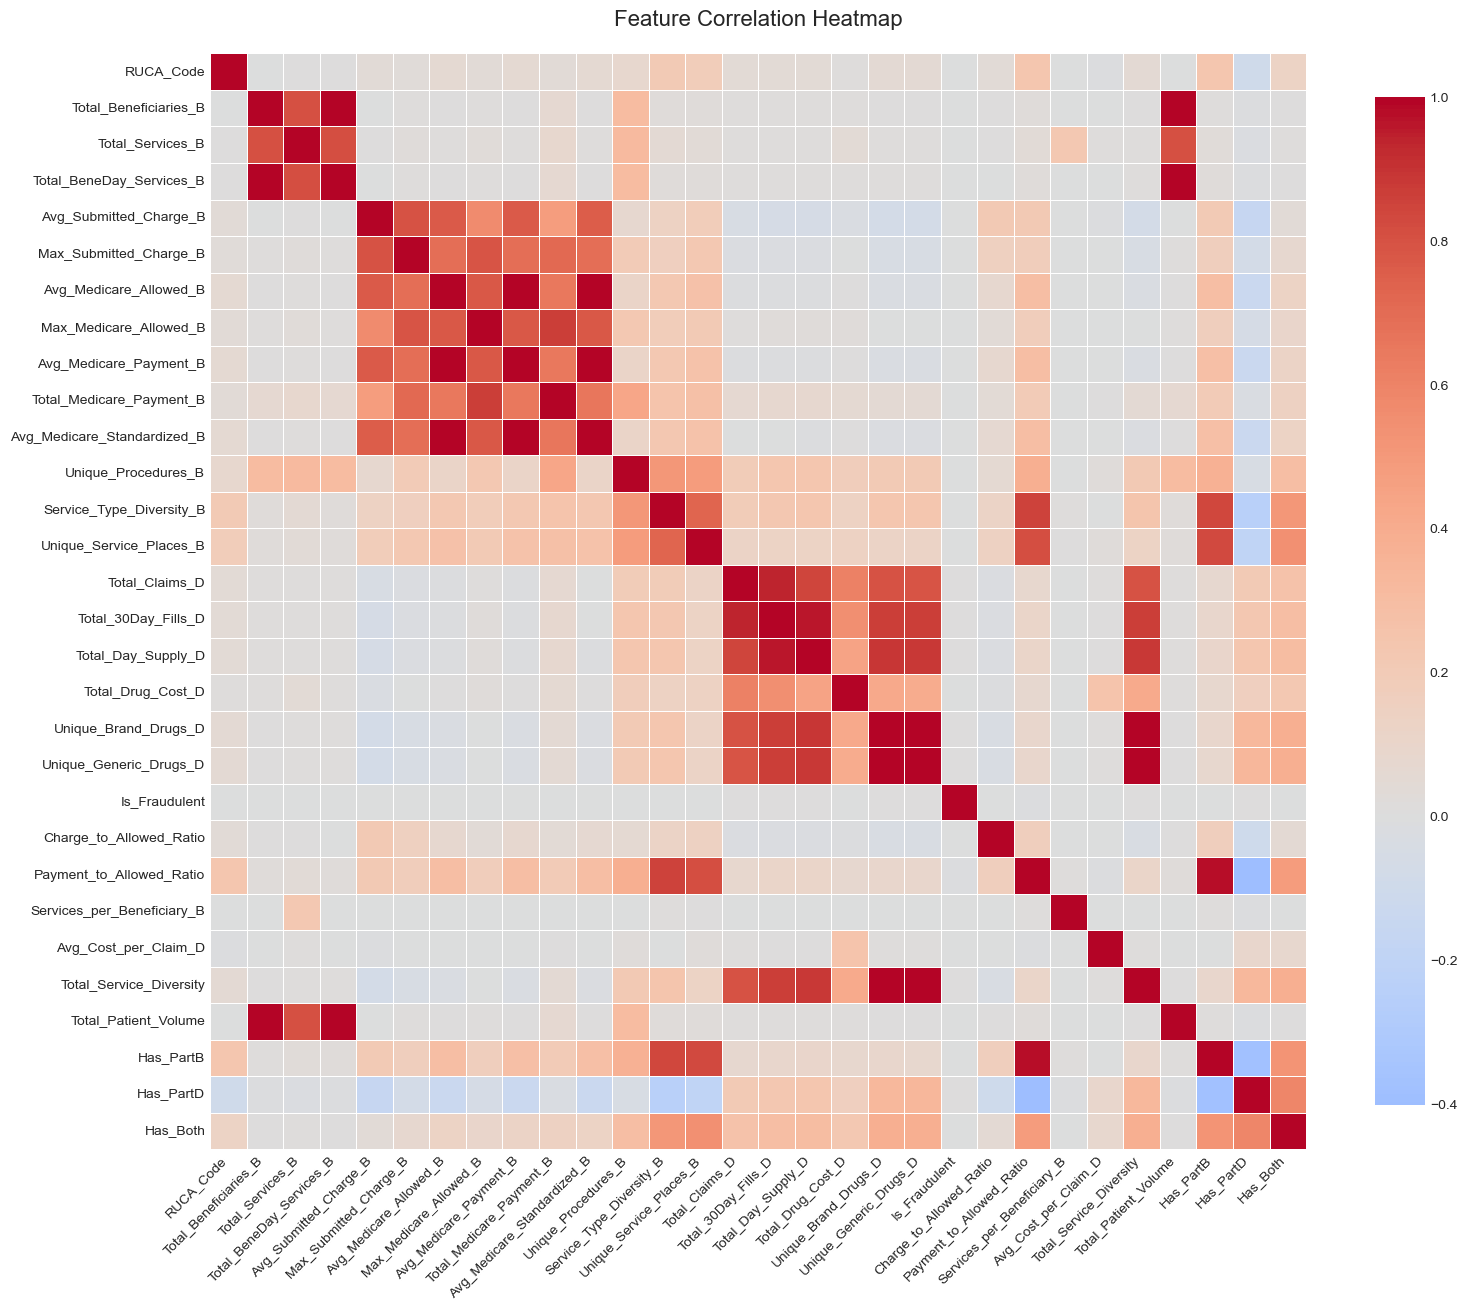


Top 15 features correlated with fraud:
Total_Claims_D                0.0075
Total_Day_Supply_D            0.0049
Has_PartD                     0.0049
Total_30Day_Fills_D           0.0049
Unique_Brand_Drugs_D          0.0044
Unique_Generic_Drugs_D        0.0042
Total_Service_Diversity       0.0042
Total_Drug_Cost_D             0.0025
Total_Services_B              0.0002
Total_BeneDay_Services_B      0.0000
Total_Patient_Volume         -0.0000
Total_Beneficiaries_B        -0.0000
Services_per_Beneficiary_B   -0.0000
Avg_Cost_per_Claim_D         -0.0005
Max_Medicare_Allowed_B       -0.0013
Name: Is_Fraudulent, dtype: float64

Bottom 10 features (negative correlation with fraud):
Max_Submitted_Charge_B        -0.0023
Unique_Procedures_B           -0.0025
Avg_Medicare_Allowed_B        -0.0026
Avg_Medicare_Standardized_B   -0.0027
Avg_Medicare_Payment_B        -0.0027
Avg_Submitted_Charge_B        -0.0028
Service_Type_Diversity_B      -0.0060
Unique_Service_Places_B       -0.0068
Has_PartB 

In [53]:

print("Analyzing feature correlations...")

# Select only numeric features for correlation
numeric_features = providers_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_features.remove('NPI') 


corr_matrix = providers_df[numeric_features].corr()


plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Heatmap', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'figures' / 'correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


fraud_correlations = corr_matrix['Is_Fraudulent'].sort_values(ascending=False)
print("\nTop 15 features correlated with fraud:")
print(fraud_correlations.head(16)[1:]) 

print("\nBottom 10 features (negative correlation with fraud):")
print(fraud_correlations.tail(10))

## 8. Statistical Feature Selection

We'll use statistical methods to identify and remove redundant features:
1. **Correlation Analysis**: Remove highly correlated features (multicollinearity)
2. **Variance Threshold**: Remove low-variance features
3. **Chi-Square Test**: Statistical significance for feature-target relationship

### 8.1

In [54]:
from sklearn.feature_selection import VarianceThreshold

print("SECTION 8: STATISTICAL FEATURE SELECTION")


# Drop non-predictive columns (identifiers, labels, categorical descriptors)
columns_to_drop_for_selection = ['NPI', 'Is_Fraudulent', 'Provider_Name', 'Provider_FirstName', 
                                   'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Data_Source']
existing_cols_to_drop_selection = [col for col in columns_to_drop_for_selection if col in providers_df.columns]

print(f"\n  • Dropping {len(existing_cols_to_drop_selection)} non-predictive columns: {existing_cols_to_drop_selection}")

X_all = providers_df.drop(columns=existing_cols_to_drop_selection, axis=1)
y_all = providers_df['Is_Fraudulent']

print(f"\n✓ Total predictive features: {X_all.shape[1]}")
print(f"✓ Total samples: {X_all.shape[0]:,}")
print(f"✓ Fraud cases: {y_all.sum():,} ({y_all.sum()/len(y_all)*100:.2f}%)")

# STEP 0: Train-Test Split (BEFORE feature selection to prevent data leakage)
print("\n" + "-"*80)
print("STEP 0: TRAIN-TEST SPLIT (80-20)")
print("-"*80)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_all
)

print(f"\nTrain set: {X_train.shape[0]:,} samples ({y_train.sum():,} fraud cases, {y_train.sum()/len(y_train)*100:.2f}%)")
print(f"Test set:  {X_test.shape[0]:,} samples ({y_test.sum():,} fraud cases, {y_test.sum()/len(y_test)*100:.2f}%)")

# Step 1: Remove highly correlated features (multicollinearity) - TRAIN DATA ONLY
print("\n" + "-"*80)
print("STEP 1: CORRELATION-BASED FEATURE REMOVAL (on training data)")
print("-"*80)

correlation_matrix = X_train.corr().abs()
high_corr_threshold = 0.90
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find features to drop
to_drop_corr = [column for column in upper_triangle.columns 
                if any(upper_triangle[column] > high_corr_threshold)]

print(f"\nCorrelation threshold: {high_corr_threshold}")
print(f"Highly correlated features to remove: {len(to_drop_corr)}")
if to_drop_corr:
    print("\nFeatures removed due to high correlation:")
    for feat in to_drop_corr:
        correlated_with = upper_triangle[feat][upper_triangle[feat] > high_corr_threshold].index.tolist()
        if correlated_with:
            print(f"  • {feat} (corr > {high_corr_threshold} with: {correlated_with[0]})")

# Apply to both train and test
X_train_reduced = X_train.drop(columns=to_drop_corr, errors='ignore')
X_test_reduced = X_test.drop(columns=to_drop_corr, errors='ignore')
print(f"\n✓ Features after correlation removal: {X_train_reduced.shape[1]}")

# Step 2: Variance Threshold - TRAIN DATA ONLY
print("\n" + "-"*80)
print("STEP 2: VARIANCE THRESHOLD (on training data)")
print("-"*80)

var_threshold = 0.01
selector_var = VarianceThreshold(threshold=var_threshold)
selector_var.fit(X_train_reduced)

feature_variances = X_train_reduced.var()
low_var_features = feature_variances[feature_variances < var_threshold].index.tolist()

print(f"\nVariance threshold: {var_threshold}")
print(f"Low variance features to remove: {len(low_var_features)}")
if low_var_features:
    print("\nLow variance features:")
    for feat in low_var_features:
        print(f"  • {feat} (variance: {feature_variances[feat]:.6f})")

# Apply transformation to both train and test
X_train_reduced = pd.DataFrame(
    selector_var.transform(X_train_reduced),
    columns=X_train_reduced.columns[selector_var.get_support()],
    index=X_train_reduced.index
)
X_test_reduced = pd.DataFrame(
    selector_var.transform(X_test_reduced),
    columns=X_test_reduced.columns[selector_var.get_support()],
    index=X_test_reduced.index
)
print(f"\n✓ Features after variance threshold: {X_train_reduced.shape[1]}")

# Step 3: Chi-Square Test - TRAIN DATA ONLY
print("\n" + "-"*80)
print("STEP 3: CHI-SQUARE TEST (on training data)")
print("-"*80)

non_negative_features = X_train_reduced.columns[(X_train_reduced >= 0).all()].tolist()

if len(non_negative_features) > 0:
    print(f"\nNon-negative features for chi-square test: {len(non_negative_features)}")
    
    chi_scores, p_values = chi2(X_train_reduced[non_negative_features], y_train)
    
    chi_scores_df = pd.DataFrame({
        'Feature': non_negative_features,
        'Chi2_Score': chi_scores,
        'P_Value': p_values
    }).sort_values('Chi2_Score', ascending=False)
    
    print("\nTop 10 features by Chi-Square score:")
    print(chi_scores_df.head(10).to_string(index=False))
    
    significant_features = chi_scores_df[chi_scores_df['P_Value'] < 0.05]['Feature'].tolist()
    print(f"\nStatistically significant features (p < 0.05): {len(significant_features)}")
else:
    print("\n⚠️ No non-negative features available for chi-square test")
    significant_features = []
    chi_scores_df = None

# Summary
print("\n" + "="*80)
print("FEATURE SELECTION SUMMARY")
print("="*80)

print(f"\n1. Original features: {X_all.shape[1]}")
print(f"2. After correlation removal: {X_all.shape[1] - len(to_drop_corr)}")
print(f"3. After variance threshold: {X_train_reduced.shape[1]}")
print(f"4. Statistically significant (chi-square): {len(significant_features)}")

print(f"\n✓ Final features: {X_train_reduced.shape[1]}")
print(f"✓ Features removed: {X_all.shape[1] - X_train_reduced.shape[1]}")
print(f"✓ Reduction: {(1 - X_train_reduced.shape[1]/X_all.shape[1])*100:.1f}%")

selected_features_statistical = X_train_reduced.columns.tolist()
print(f"\nSelected features list ({len(selected_features_statistical)} features):")
for i, feat in enumerate(selected_features_statistical, 1):
    print(f"  {i}. {feat}")
feature_selection_results = {
    'original_features': X_all.columns.tolist(),
    'selected_features': selected_features_statistical,
    'removed_by_correlation': to_drop_corr,
    'removed_by_variance': low_var_features,
    'chi_scores': chi_scores_df
}

print("\n✓ STATISTICAL FEATURE SELECTION COMPLETE")
print("✓ Feature selection applied on training data only - no data leakage!")

SECTION 8: STATISTICAL FEATURE SELECTION

  • Dropping 9 non-predictive columns: ['NPI', 'Is_Fraudulent', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Data_Source']

✓ Total predictive features: 29
✓ Total samples: 1,572,414
✓ Fraud cases: 270 (0.02%)

--------------------------------------------------------------------------------
STEP 0: TRAIN-TEST SPLIT (80-20)
--------------------------------------------------------------------------------

Train set: 1,257,931 samples (216 fraud cases, 0.02%)
Test set:  314,483 samples (54 fraud cases, 0.02%)

--------------------------------------------------------------------------------
STEP 1: CORRELATION-BASED FEATURE REMOVAL (on training data)
--------------------------------------------------------------------------------

Correlation threshold: 0.9
Highly correlated features to remove: 9

Features removed due to high correlation:
  • Total_BeneDay_Services_B (corr > 0.9 with: Total_Beneficiari

## 9. Data Scaling & Class Balancing

### 9.1 Data Summary (Using Pre-Split Data from Section 8.1)

In [55]:

print("="*80)
print("DATA PREPARATION SUMMARY")
print("="*80)

print("\n📊 Using pre-split data from Section 8.1:")
print(f"   • Train-test split already performed (80-20 stratified)")
print(f"   • Feature selection applied on training data only")
print(f"   • No data leakage - test data never influenced feature selection")

print(f"\n✓ Training set shape: {X_train_reduced.shape}")
print(f"✓ Test set shape: {X_test_reduced.shape}")

print(f"\n✓ Training fraud rate: {y_train.mean()*100:.4f}% ({y_train.sum():,} / {len(y_train):,})")
print(f"✓ Test fraud rate: {y_test.mean()*100:.4f}% ({y_test.sum():,} / {len(y_test):,})")

print(f"\n✓ Selected features for modeling: {len(selected_features_statistical)}")
print("\nFeature list:")
for i, feat in enumerate(selected_features_statistical, 1):
    print(f"  {i:2d}. {feat}")

# Use the reduced datasets for modeling
X_train = X_train_reduced.copy()
X_test = X_test_reduced.copy()
feature_names = X_train.columns.tolist()

print(f"\n✓ Ready for modeling with {len(feature_names)} features")
print("="*80)

DATA PREPARATION SUMMARY

📊 Using pre-split data from Section 8.1:
   • Train-test split already performed (80-20 stratified)
   • Feature selection applied on training data only
   • No data leakage - test data never influenced feature selection

✓ Training set shape: (1257931, 20)
✓ Test set shape: (314483, 20)

✓ Training fraud rate: 0.0172% (216 / 1,257,931)
✓ Test fraud rate: 0.0172% (54 / 314,483)

✓ Selected features for modeling: 20

Feature list:
   1. RUCA_Code
   2. Total_Beneficiaries_B
   3. Total_Services_B
   4. Avg_Submitted_Charge_B
   5. Max_Submitted_Charge_B
   6. Avg_Medicare_Allowed_B
   7. Max_Medicare_Allowed_B
   8. Total_Medicare_Payment_B
   9. Unique_Procedures_B
  10. Service_Type_Diversity_B
  11. Unique_Service_Places_B
  12. Total_Claims_D
  13. Total_Drug_Cost_D
  14. Unique_Brand_Drugs_D
  15. Charge_to_Allowed_Ratio
  16. Payment_to_Allowed_Ratio
  17. Services_per_Beneficiary_B
  18. Avg_Cost_per_Claim_D
  19. Has_PartD
  20. Has_Both

✓ Ready for mo

### 9.2 Handle Class Imbalance

In [56]:
# Handle class imbalance with SMOTE
print("Handling class imbalance with SMOTE...")

print(f"Before SMOTE:")
print(f"  Class 0 (Non-Fraud): {(y_train == 0).sum()}")
print(f"  Class 1 (Fraud): {(y_train == 1).sum()}")
print(f"  Imbalance ratio: {(y_train == 0).sum() / (y_train == 1).sum():.2f}:1")

# Apply SMOTE to training data only
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"\nAfter SMOTE:")
print(f"  Class 0 (Non-Fraud): {(y_train_balanced == 0).sum()}")
print(f"  Class 1 (Fraud): {(y_train_balanced == 1).sum()}")
print(f"  Imbalance ratio: {(y_train_balanced == 0).sum() / (y_train_balanced == 1).sum():.2f}:1")

print(f"\nNew training set shape: {X_train_balanced.shape}")

Handling class imbalance with SMOTE...
Before SMOTE:
  Class 0 (Non-Fraud): 1257715
  Class 1 (Fraud): 216
  Imbalance ratio: 5822.75:1

After SMOTE:
  Class 0 (Non-Fraud): 1257715
  Class 1 (Fraud): 1257715
  Imbalance ratio: 1.00:1

New training set shape: (2515430, 20)


### 9.3 Feature Scaling

In [57]:
# Feature Scaling
print("Scaling features using RobustScaler...")

# Use RobustScaler (better for outliers)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print(f"✓ Training data scaled: {X_train_scaled.shape}")
print(f"✓ Test data scaled: {X_test_scaled.shape}")

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

print("\nData is ready for model training!")

Scaling features using RobustScaler...
✓ Training data scaled: (2515430, 20)
✓ Test data scaled: (314483, 20)

Data is ready for model training!


### 9.4 Model Evaluation Function

Define the evaluation function before training models.

In [58]:
def evaluate_model(y_true, y_pred, y_pred_proba, model_name):
    """
    Comprehensive model evaluation
    """
    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Print metrics
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"MCC:       {mcc:.4f}")
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    print(f"\nConfusion Matrix:")
    print(cm)
    
    # Classification report
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    return {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc,
        'mcc': mcc
    }

print("✓ Model evaluation function defined")

✓ Model evaluation function defined


## 10. Baseline Models

In [59]:

results_list = []

print("="*80)
print("MODEL TRAINING AND EVALUATION")
print("="*80)
print("\nInitialized results tracking...")
print(f"Test set size: {len(y_test):,} samples")
print(f"Test set fraud cases: {y_test.sum():,} ({y_test.sum()/len(y_test)*100:.2f}%)")

y_test.value_counts()

MODEL TRAINING AND EVALUATION

Initialized results tracking...
Test set size: 314,483 samples
Test set fraud cases: 54 (0.02%)


Is_Fraudulent
0    314429
1        54
Name: count, dtype: int64

### 10.1 Logistic Regression

In [60]:
# Logistic Regression Baseline Model
print("Training Logistic Regression Model...")

lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train_balanced)

y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

lr_results = evaluate_model(y_test, y_pred_lr, y_pred_proba_lr, "Logistic Regression")
results_list.append(lr_results)

print("\n✓ Logistic Regression training complete!")

Training Logistic Regression Model...
Accuracy:  0.6733
Precision: 0.0003
Recall:    0.6296
F1-Score:  0.0007
ROC-AUC:   0.7023
MCC:       0.0085

Confusion Matrix:
[[211710 102719]
 [    20     34]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.67      0.80    314429
           1       0.00      0.63      0.00        54

    accuracy                           0.67    314483
   macro avg       0.50      0.65      0.40    314483
weighted avg       1.00      0.67      0.80    314483


✓ Logistic Regression training complete!


## 11. Advanced Machine Learning Models

### 11.1 Random Forest Model

In [61]:
# Random Forest Classifier
print("Training Random Forest Model...")

# Train model with reasonable parameters
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight='balanced'
)
rf_model.fit(X_train_scaled, y_train_balanced)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
rf_results = evaluate_model(y_test, y_pred_rf, y_pred_proba_rf, "Random Forest")
results_list.append(rf_results)

# Feature importance
feature_importance_rf = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance_rf.head(10))

print("\n✓ Random Forest training complete!")

Training Random Forest Model...
Accuracy:  0.9854
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.6410
MCC:       -0.0016

Confusion Matrix:
[[309895   4534]
 [    54      0]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99    314429
           1       0.00      0.00      0.00        54

    accuracy                           0.99    314483
   macro avg       0.50      0.49      0.50    314483
weighted avg       1.00      0.99      0.99    314483


Top 10 Most Important Features:
                       feature  importance
12           Total_Drug_Cost_D      0.1273
13        Unique_Brand_Drugs_D      0.0965
11              Total_Claims_D      0.0946
15    Payment_to_Allowed_Ratio      0.0913
17        Avg_Cost_per_Claim_D      0.0883
10     Unique_Service_Places_B      0.0759
9     Service_Type_Diversity_B      0.0659
0                    RUCA_Code      0.0513
16  Services_per_Beneficiary_B    

### 11.2 XGBoost Model

In [62]:
print("Training XGBoost Model...")

try:
    import xgboost as xgb
    
    xgb_model = xgb.XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        scale_pos_weight=(len(y_train_balanced) - y_train_balanced.sum()) / y_train_balanced.sum(),
        eval_metric='logloss'
    )
    xgb_model.fit(X_train_scaled, y_train_balanced)
    
    # Predictions
    y_pred_xgb = xgb_model.predict(X_test_scaled)
    y_pred_proba_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]
    
    # Evaluate
    xgb_results = evaluate_model(y_test, y_pred_xgb, y_pred_proba_xgb, "XGBoost")
    results_list.append(xgb_results)
    
    # Feature importance
    feature_importance_xgb = pd.DataFrame({
        'feature': feature_names,
        'importance': xgb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features (XGBoost):")
    print(feature_importance_xgb.head(10))
    
    print("\n✓ XGBoost training complete!")
    
except ImportError:
    print("⚠ XGBoost not available, skipping...")
    print("Install with: pip install xgboost")

Training XGBoost Model...
Accuracy:  0.9660
Precision: 0.0003
Recall:    0.0556
F1-Score:  0.0006
ROC-AUC:   0.6154
MCC:       0.0016

Confusion Matrix:
[[303789  10640]
 [    51      3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98    314429
           1       0.00      0.06      0.00        54

    accuracy                           0.97    314483
   macro avg       0.50      0.51      0.49    314483
weighted avg       1.00      0.97      0.98    314483


Top 10 Most Important Features (XGBoost):
                       feature  importance
10     Unique_Service_Places_B      0.1610
19                    Has_Both      0.1405
15    Payment_to_Allowed_Ratio      0.1106
18                   Has_PartD      0.0900
9     Service_Type_Diversity_B      0.0765
13        Unique_Brand_Drugs_D      0.0680
8          Unique_Procedures_B      0.0634
16  Services_per_Beneficiary_B      0.0386
11              Total_Claims_D 

### 11.3 LightGBM Model

In [63]:
print("Training LightGBM Model...")

try:
    import lightgbm as lgb

    lgb_model = lgb.LGBMClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight='balanced',
        verbosity=-1
    )
    lgb_model.fit(X_train_scaled, y_train_balanced)
    
    # Predictions
    y_pred_lgb = lgb_model.predict(X_test_scaled)
    y_pred_proba_lgb = lgb_model.predict_proba(X_test_scaled)[:, 1]
    
    # Evaluate
    lgb_results = evaluate_model(y_test, y_pred_lgb, y_pred_proba_lgb, "LightGBM")
    results_list.append(lgb_results)
    
    # Feature importance
    feature_importance_lgb = pd.DataFrame({
        'feature': feature_names,
        'importance': lgb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features (LightGBM):")
    print(feature_importance_lgb.head(10))
    
    print("\n✓ LightGBM training complete!")
    
except ImportError:
    print("⚠ LightGBM not available, skipping...")
    print("Install with: pip install lightgbm")

Training LightGBM Model...
Accuracy:  0.9751
Precision: 0.0003
Recall:    0.0370
F1-Score:  0.0005
ROC-AUC:   0.5979
MCC:       0.0010

Confusion Matrix:
[[306648   7781]
 [    52      2]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    314429
           1       0.00      0.04      0.00        54

    accuracy                           0.98    314483
   macro avg       0.50      0.51      0.49    314483
weighted avg       1.00      0.98      0.99    314483


Top 10 Most Important Features (LightGBM):
                       feature  importance
12           Total_Drug_Cost_D         977
13        Unique_Brand_Drugs_D         666
11              Total_Claims_D         540
8          Unique_Procedures_B         500
17        Avg_Cost_per_Claim_D         484
15    Payment_to_Allowed_Ratio         317
0                    RUCA_Code         305
16  Services_per_Beneficiary_B         273
1        Total_Beneficiaries_

### 11.4 CatBoost Model

In [64]:
if CatBoostClassifier is not None:
    print("Training CatBoost Model...")
    
    # Train model
    cb_model = CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        verbose=False,
        auto_class_weights='Balanced'
    )
    cb_model.fit(X_train_scaled, y_train_balanced)
    
    # Predictions
    y_pred_cb = cb_model.predict(X_test_scaled)
    y_pred_proba_cb = cb_model.predict_proba(X_test_scaled)[:, 1]
    
    # Evaluate
    cb_results = evaluate_model(y_test, y_pred_cb, y_pred_proba_cb, "CatBoost")
    results_list.append(cb_results)
    
    # Feature importance
    feature_importance_cb = pd.DataFrame({
        'feature': feature_names,
        'importance': cb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features (CatBoost):")
    print(feature_importance_cb.head(10))
    
    print("\n✓ CatBoost training complete!")
else:
    print("⚠ CatBoost not available, skipping...")
    print("Install with: pip install catboost")

⚠ CatBoost not available, skipping...
Install with: pip install catboost


### 11.5 Support Vector Machine

In [65]:
# Train SVM model

### 11.6 Neural Network (MLP)

In [66]:
# Train Multi-Layer Perceptron

## 12. Model Evaluation & Comparison

### 12.1 Performance Metrics

In [67]:
# Note: evaluate_model function is defined in Section 9.4
# This section uses the results collected in results_list from all models

print("Model evaluation function already defined in Section 9.4")

Model evaluation function already defined in Section 9.4


### 12.2 ROC and Precision-Recall Curves

In [68]:
def plot_roc_pr_curves(y_true, y_pred_proba, model_name):
    """
    Plot ROC and Precision-Recall curves
    """
    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    
    # PR curve
    precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_pred_proba)
    pr_auc = auc(recall_vals, precision_vals)
    
    # Create subplots
    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=('ROC Curve', 'Precision-Recall Curve')
    )
    
    # ROC curve
    fig.add_trace(
        go.Scatter(x=fpr, y=tpr, name=f'{model_name} (AUC = {roc_auc:.3f})',
                   mode='lines'),
        row=1, col=1
    )
    fig.add_trace(
        go.Scatter(x=[0, 1], y=[0, 1], name='Random',
                   mode='lines', line=dict(dash='dash')),
        row=1, col=1
    )
    
    # PR curve
    fig.add_trace(
        go.Scatter(x=recall_vals, y=precision_vals,
                   name=f'{model_name} (AUC = {pr_auc:.3f})',
                   mode='lines'),
        row=1, col=2
    )
    
    # Update layout
    fig.update_xaxes(title_text='False Positive Rate', row=1, col=1)
    fig.update_yaxes(title_text='True Positive Rate', row=1, col=1)
    fig.update_xaxes(title_text='Recall', row=1, col=2)
    fig.update_yaxes(title_text='Precision', row=1, col=2)
    
    fig.update_layout(height=400, showlegend=True,
                      title_text=f'{model_name} - Performance Curves')
    fig.show()

### 12.3 Model Comparison Table

In [69]:
# Model Comparison Table
print("Model Comparison Summary")
print("="*80)

# Create comparison DataFrame
comparison_df = pd.DataFrame(results_list)
comparison_df = comparison_df.sort_values('f1', ascending=False)

print(comparison_df.to_string(index=False))

# Visualize comparison
fig = go.Figure()

metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
for metric in metrics:
    fig.add_trace(go.Bar(
        name=metric.upper(),
        x=comparison_df['model'],
        y=comparison_df[metric],
        text=comparison_df[metric].round(4),
        textposition='auto'
    ))

fig.update_layout(
    title='Model Performance Comparison',
    xaxis_title='Model',
    yaxis_title='Score',
    barmode='group',
    height=500
)
fig.show()

# Save comparison
comparison_df.to_csv(OUTPUT_DIR / 'reports' / 'model_comparison.csv', index=False)
print("\n✓ Model comparison saved to reports/model_comparison.csv")

Model Comparison Summary
              model  accuracy  precision  recall     f1  roc_auc     mcc
Logistic Regression    0.6733     0.0003  0.6296 0.0007   0.7023  0.0085
            XGBoost    0.9660     0.0003  0.0556 0.0006   0.6154  0.0016
           LightGBM    0.9751     0.0003  0.0370 0.0005   0.5979  0.0010
      Random Forest    0.9854     0.0000  0.0000 0.0000   0.6410 -0.0016



✓ Model comparison saved to reports/model_comparison.csv


## 13. Model Interpretation

### 13.1 SHAP Values Analysis

In [70]:
# SHAP analysis for model interpretation
# explainer = shap.TreeExplainer(model)
# shap_values = explainer.shap_values(X_test)

### 13.2 Feature Importance

In [71]:
# Plot feature importance from tree-based models

### 13.3 LIME Explanations

In [72]:
# Local interpretable model-agnostic explanations for individual predictions

## 14. Model Optimization

### 14.1 Hyperparameter Tuning

In [80]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1a  Hyperparameter Tuning — Random Forest
# ═══════════════════════════════════════════════════════════════════════
# Key fixes over base RF:
#   1. Train on ORIGINAL (pre-SMOTE) data — SMOTE caused test Recall=0
#      because trees memorised synthetic patterns that don't exist in test.
#   2. class_weight='balanced' compensates for the ~5,800:1 imbalance.
#   3. Calibrate RF probabilities (isotonic) — RF leaf probabilities are
#      unreliable on extreme imbalance without calibration.
#   4. Threshold via Youden's J (TPR−FPR) on a validation split —
#      more robust than default 0.5 on imbalanced data.

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

print("=" * 60)
print("Section 14.1a  Hyperparameter Tuning: Random Forest")
print("=" * 60)

# ── 1. Scale original (pre-SMOTE) training data ────────────────────────
X_train_orig_scaled = pd.DataFrame(
    scaler.transform(X_train), columns=feature_names, index=X_train.index
)
print(f"\nTraining samples : {len(y_train):,}  (original, pre-SMOTE)")
print(f"Fraud cases      : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

# ── 2. Hold-out 20% for calibration & threshold selection ──────────────
X_tr_rf, X_val_rf, y_tr_rf, y_val_rf = train_test_split(
    X_train_orig_scaled, y_train,
    test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
)
print(f"Train subset : {len(y_tr_rf):,} | Val subset : {len(y_val_rf):,}")
print(f"Val fraud    : {int(y_val_rf.sum()):,}")

# ── 3. Improved search space ───────────────────────────────────────────
# New additions vs previous version:
#   • max_samples  — bootstrap subsampling fraction; using < 1.0 acts like
#                    extra regularisation and speeds up each tree on 1.2M rows
#   • min_samples_split — controls early stopping of splits (pairs with leaf)
# 15 iterations keeps runtime reasonable (~15–20 min)
cv_rf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_param_dist = {
    "n_estimators"     : [100, 200, 300, 400],
    "max_depth"        : [5, 8, 12, 15, 20],
    "min_samples_leaf" : [4, 8, 16],
    "min_samples_split": [5, 10, 20],
    "max_features"     : ["sqrt", "log2"],
    "class_weight"     : ["balanced", "balanced_subsample"],
    "max_samples"      : [0.5, 0.7, 0.9, None],  # bootstrap fraction
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=cv_rf,
    n_jobs=-1,
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True,
)

print("\nTuning Random Forest (15 iterations × 3 folds = 45 fits)…")
rf_search.fit(X_tr_rf, y_tr_rf)
best_rf_params = rf_search.best_params_
print(f"\nBest RF params  : {best_rf_params}")
print(f"Best CV ROC-AUC : {rf_search.best_score_:.4f}")

# ── 4. Probability calibration (isotonic regression) ───────────────────
best_rf_uncalib = rf_search.best_estimator_
calibrated_rf = CalibratedClassifierCV(best_rf_uncalib, cv="prefit", method="isotonic")
calibrated_rf.fit(X_val_rf, y_val_rf)

val_proba_rf = calibrated_rf.predict_proba(X_val_rf)[:, 1]
fraud_probas = val_proba_rf[y_val_rf == 1]
print(f"\nCalibrated fraud probabilities — min: {fraud_probas.min():.4f}  "
      f"max: {fraud_probas.max():.4f}  mean: {fraud_probas.mean():.4f}")

# ── 5. Threshold via Youden's J = TPR − FPR ────────────────────────────
fprs_rf, tprs_rf, roc_thr_rf = roc_curve(y_val_rf, val_proba_rf)
youden_rf    = tprs_rf - fprs_rf
best_idx_rf  = int(np.argmax(youden_rf))
best_thr_rf  = float(roc_thr_rf[best_idx_rf])
print(f"\nYouden's J threshold : {best_thr_rf:.4f}")
print(f"  Val TPR (recall)   : {tprs_rf[best_idx_rf]:.4f}")
print(f"  Val FPR            : {fprs_rf[best_idx_rf]:.4f}")

# ── 6. Refit best params on full training set + calibrate ──────────────
best_rf_full = RandomForestClassifier(
    **best_rf_params, random_state=RANDOM_STATE, n_jobs=-1
)
best_rf_full.fit(X_train_orig_scaled, y_train)
calibrated_rf_final = CalibratedClassifierCV(
    best_rf_full, cv="prefit", method="isotonic"
)
calibrated_rf_final.fit(X_val_rf, y_val_rf)
best_rf_model = calibrated_rf_final

# ── 7. Evaluate on test set ─────────────────────────────────────────────
rf_tuned_proba  = best_rf_model.predict_proba(X_test_scaled)[:, 1]
rf_tuned_pred   = (rf_tuned_proba >= best_thr_rf).astype(int)
rf_tuned_results = evaluate_model(
    y_test, rf_tuned_pred, rf_tuned_proba, "Random Forest (Tuned)"
)
results_list.append(rf_tuned_results)
print("\n✓ Random Forest tuning complete!")

Section 14.1a  Hyperparameter Tuning: Random Forest

Training samples : 1,257,931  (original, pre-SMOTE)
Fraud cases      : 216  (0.0172%)
Train subset : 1,006,344 | Val subset : 251,587
Val fraud    : 43

Tuning Random Forest (15 iterations × 3 folds = 45 fits)…
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best RF params  : {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 8, 'max_samples': 0.7, 'max_features': 'log2', 'max_depth': 5, 'class_weight': 'balanced_subsample'}
Best CV ROC-AUC : 0.7284

Calibrated fraud probabilities — min: 0.0001  max: 0.0078  mean: 0.0005

Youden's J threshold : 0.0004
  Val TPR (recall)   : 0.4884
  Val FPR            : 0.1510
Accuracy:  0.8978
Precision: 0.0004
Recall:    0.2407
F1-Score:  0.0008
ROC-AUC:   0.7068
MCC:       0.0060

Confusion Matrix:
[[282327  32102]
 [    41     13]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95    314429
    

In [82]:

# ═══════════════════════════════════════════════════════════════════════
# Section 14.1b  Hyperparameter Tuning — XGBoost
# ═══════════════════════════════════════════════════════════════════════
# All RF improvements now applied + XGBoost-specific additions:
#   1. Train on ORIGINAL (pre-SMOTE) data.
#   2. scale_pos_weight = n_non_fraud / n_fraud (equivalent to class_weight).
#   3. Probability calibration (isotonic) — now added, same as RF.
#      XGBoost sigmoid outputs are NOT well-calibrated on extreme imbalance.
#   4. Threshold via Youden's J on a held-out validation split.
#   5. tree_method='hist' — histogram-based: 5-10x faster, allows more iters.
#   6. max_delta_step — XGBoost's own recommendation for imbalanced data;
#      limits gradient step size to stabilise fraud-class learning.
#   7. reg_alpha / reg_lambda — L1/L2 regularisation to reduce overfitting.

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

print("=" * 60)
print("Section 14.1b  Hyperparameter Tuning: XGBoost")
print("=" * 60)

if xgb is None:
    print("⚠  XGBoost not available — skipping.")
else:
    # ── 1. Original-scale data (rebuild if 14.1a was skipped) ──────────
    if "X_train_orig_scaled" not in dir():
        X_train_orig_scaled = pd.DataFrame(
            scaler.transform(X_train), columns=feature_names, index=X_train.index
        )

    original_pos_weight = float((y_train == 0).sum()) / float((y_train == 1).sum())
    print(f"\nImbalance ratio  : {original_pos_weight:.1f}x")
    print(f"Fraud cases      : {int(y_train.sum()):,}  ({y_train.mean():.4%})")

    # ── 2. Hold-out 20% for calibration & threshold selection ──────────
    X_tr_xgb, X_val_xgb, y_tr_xgb, y_val_xgb = train_test_split(
        X_train_orig_scaled, y_train,
        test_size=0.20, random_state=RANDOM_STATE + 1, stratify=y_train
    )
    print(f"Train subset : {len(y_tr_xgb):,} | Val subset : {len(y_val_xgb):,}")
    print(f"Val fraud    : {int(y_val_xgb.sum()):,}")

    # ── 3. Improved search space ─────────────────────────────────────────
    # New vs previous: reg_alpha, reg_lambda, max_delta_step; tree_method fixed
    cv_xgb = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

    xgb_param_dist = {
        "n_estimators"   : [100, 200, 300, 400],
        "max_depth"      : [3, 4, 5, 6],
        "learning_rate"  : [0.05, 0.1, 0.15, 0.2],
        "subsample"      : [0.7, 0.8, 0.9],
        "colsample_bytree": [0.7, 0.8, 0.9],
        "min_child_weight": [1, 5, 10, 20],
        "gamma"          : [0, 0.1, 0.3],
        "max_delta_step" : [1, 5, 10],      # stabilises updates on imbalanced data
        "reg_alpha"      : [0, 0.1, 0.5],   # L1 sparsity
        "reg_lambda"     : [1.0, 2.0, 5.0], # L2 shrinkage
    }

    xgb_search = RandomizedSearchCV(
        estimator=xgb.XGBClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            eval_metric="logloss",
            scale_pos_weight=original_pos_weight,
        ),
        param_distributions=xgb_param_dist,
        n_iter=15,
        scoring="roc_auc",
        cv=cv_xgb,
        n_jobs=-1,
        verbose=1,
        random_state=RANDOM_STATE,
        refit=True,
    )

    print("\nTuning XGBoost (15 iterations × 3 folds = 45 fits)…")
    xgb_search.fit(X_tr_xgb, y_tr_xgb)
    best_xgb_params = xgb_search.best_params_
    print(f"\nBest XGB params  : {best_xgb_params}")
    print(f"Best CV ROC-AUC  : {xgb_search.best_score_:.4f}")

    # ── 4. Probability calibration (isotonic) — same as RF ──────────────
    best_xgb_uncalib = xgb_search.best_estimator_
    calibrated_xgb = CalibratedClassifierCV(
        best_xgb_uncalib, cv="prefit", method="isotonic"
    )
    calibrated_xgb.fit(X_val_xgb, y_val_xgb)

    val_proba_xgb = calibrated_xgb.predict_proba(X_val_xgb)[:, 1]
    xgb_fraud_probas = val_proba_xgb[y_val_xgb == 1]
    print(f"\nCalibrated fraud probabilities — min: {xgb_fraud_probas.min():.4f}  "
          f"max: {xgb_fraud_probas.max():.4f}  mean: {xgb_fraud_probas.mean():.4f}")

    # ── 5. Threshold via Youden's J ──────────────────────────────────────
    fprs_xgb, tprs_xgb, roc_thr_xgb = roc_curve(y_val_xgb, val_proba_xgb)
    youden_xgb   = tprs_xgb - fprs_xgb
    best_idx_xgb = int(np.argmax(youden_xgb))
    best_thr_xgb = float(roc_thr_xgb[best_idx_xgb])
    print(f"\nYouden's J threshold : {best_thr_xgb:.4f}")
    print(f"  Val TPR (recall)   : {tprs_xgb[best_idx_xgb]:.4f}")
    print(f"  Val FPR            : {fprs_xgb[best_idx_xgb]:.4f}")

    # ── 6. Refit on full training set + calibrate ────────────────────────
    best_xgb_full = xgb.XGBClassifier(
        **best_xgb_params,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        tree_method="hist",
        eval_metric="logloss",
        scale_pos_weight=original_pos_weight,
    )
    best_xgb_full.fit(X_train_orig_scaled, y_train)

    calibrated_xgb_final = CalibratedClassifierCV(
        best_xgb_full, cv="prefit", method="isotonic"
    )
    calibrated_xgb_final.fit(X_val_xgb, y_val_xgb)
    best_xgb_model = calibrated_xgb_final

    # ── 7. Evaluate on test set ──────────────────────────────────────────
    xgb_tuned_proba  = best_xgb_model.predict_proba(X_test_scaled)[:, 1]
    xgb_tuned_pred   = (xgb_tuned_proba >= best_thr_xgb).astype(int)
    xgb_tuned_results = evaluate_model(
        y_test, xgb_tuned_pred, xgb_tuned_proba, "XGBoost (Tuned)"
    )
    results_list.append(xgb_tuned_results)
    print("\n✓ XGBoost tuning complete!")


Section 14.1b  Hyperparameter Tuning: XGBoost

Imbalance ratio  : 5822.8x
Fraud cases      : 216  (0.0172%)
Train subset : 1,006,344 | Val subset : 251,587
Val fraud    : 43

Tuning XGBoost (15 iterations × 3 folds = 45 fits)…
Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best XGB params  : {'subsample': 0.9, 'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 3, 'max_delta_step': 1, 'learning_rate': 0.05, 'gamma': 0.3, 'colsample_bytree': 0.8}
Best CV ROC-AUC  : 0.7242

Calibrated fraud probabilities — min: 0.0001  max: 0.0625  mean: 0.0019

Youden's J threshold : 0.0008
  Val TPR (recall)   : 0.4651
  Val FPR            : 0.0994
Accuracy:  0.9491
Precision: 0.0004
Recall:    0.1296
F1-Score:  0.0009
ROC-AUC:   0.7197
MCC:       0.0047

Confusion Matrix:
[[298478  15951]
 [    47      7]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    314429
        

### 14.2 Ensemble Methods

In [74]:
# Create voting classifier or stacking ensemble

## 15. Model Persistence

### 15.1 Save Trained Models

In [75]:
# Save Best Performing Models
print("Saving trained models...")
print("="*60)

# Save models
joblib.dump(lr_model, OUTPUT_DIR / 'models' / 'logistic_regression_model.pkl')
joblib.dump(rf_model, OUTPUT_DIR / 'models' / 'random_forest_model.pkl')
if CatBoostClassifier is not None:
    cb_model.save_model(str(OUTPUT_DIR / 'models' / 'catboost_model.cbm'))

# Save scaler and feature names
joblib.dump(scaler, OUTPUT_DIR / 'models' / 'robust_scaler.pkl')

# Save metadata
import json
metadata = {
    'feature_names': feature_names,
    'n_features': len(feature_names),
    'training_samples': len(X_train_balanced),
    'test_samples': len(X_test),
    'fraud_rate': float(y.mean()),
    'models_trained': ['Logistic Regression', 'Random Forest', 'CatBoost'],
    'best_model_by_roc_auc': comparison_df.sort_values('roc_auc', ascending=False).iloc[0]['model'],
    'training_date': str(datetime.now()),
    'smote_applied': True,
    'scaler_used': 'RobustScaler'
}

with open(OUTPUT_DIR / 'models' / 'metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print("✓ Logistic Regression saved")
print("✓ Random Forest saved")
if CatBoostClassifier is not None:
    print("✓ CatBoost saved")
print("✓ Scaler saved")
print("✓ Metadata saved")
print("\nAll models and artifacts saved to:", OUTPUT_DIR / 'models')

Saving trained models...


NameError: name 'y' is not defined

### 15.2 Save Preprocessing Objects

In [ ]:
# Save scaler and other preprocessing objects
# joblib.dump(scaler, OUTPUT_DIR / 'models' / 'scaler.pkl')

### 15.3 Save Feature Names and Metadata

In [ ]:
# Save feature names and other metadata for future use
# import json
# metadata = {
#     'feature_names': feature_names,
#     'model_performance': results_dict,
#     'training_date': str(datetime.now())
# }
# with open(OUTPUT_DIR / 'models' / 'metadata.json', 'w') as f:
#     json.dump(metadata, f, indent=4)

## 16. Summary & Next Steps

### 16.1 Summary of Results

In [ ]:
# Final Summary and Results
print("="*80)
print("MEDICARE FRAUD DETECTION - ML PIPELINE SUMMARY")
print("="*80)

print(f"\n📊 DATASET STATISTICS:")
print(f"   • Total Providers: {len(providers_df):,}")
print(f"   • Fraudulent Providers: {providers_df['Is_Fraudulent'].sum():,}")
print(f"   • Fraud Rate: {providers_df['Is_Fraudulent'].mean()*100:.4f}%")
print(f"   • Part B Providers: {(providers_df['Has_PartB'] == 1).sum():,}")
print(f"   • Part D Prescribers: {(providers_df['Has_PartD'] == 1).sum():,}")
print(f"   • Both Part B & D: {(providers_df['Has_Both'] == 1).sum():,}")

print(f"\n🔧 FEATURE ENGINEERING:")
print(f"   • Total Features Created: {len(feature_names)}")
print(f"   • Payment Ratios: 2")
print(f"   • Intensity Metrics: 3")
print(f"   • Diversity Indicators: 1")
print(f"   • Volume Metrics: 1")
print(f"   • Participation Flags: 3")

print(f"\n🤖 MODEL TRAINING:")
print(f"   • Training Samples (after SMOTE): {len(X_train_balanced):,}")
print(f"   • Test Samples: {len(X_test):,}")
print(f"   • Models Trained: {len(results_list)}")
print(f"   • Class Balance Method: SMOTE")
print(f"   • Feature Scaling: RobustScaler")

print(f"\n📈 BEST MODEL PERFORMANCE:")
best_model = comparison_df.iloc[0]
print(f"   • Model: {best_model['model']}")
print(f"   • Accuracy: {best_model['accuracy']:.4f}")
print(f"   • Precision: {best_model['precision']:.4f}")
print(f"   • Recall: {best_model['recall']:.4f}")
print(f"   • F1-Score: {best_model['f1']:.4f}")
print(f"   • ROC-AUC: {best_model['roc_auc']:.4f}")
print(f"   • MCC: {best_model['mcc']:.4f}")

print(f"\n💾 OUTPUTS SAVED:")
print(f"   • Models: {OUTPUT_DIR / 'models'}")
print(f"   • Figures: {OUTPUT_DIR / 'figures'}")
print(f"   • Reports: {OUTPUT_DIR / 'reports'}")

print("\n" + "="*80)
print("✅ MACHINE LEARNING PIPELINE COMPLETE!")
print("="*80)

print("\n📝 Next Steps:")
print("   1. Review model performance metrics")
print("   2. Analyze feature importance")
print("   3. Fine-tune hyperparameters")
print("   4. Implement model interpretation (SHAP/LIME)")
print("   5. Proceed with LLM integration for fraud explanations")
print("   6. Refer to PROJECT_ROADMAP.md for complete workflow")

print("\n🎯 Ready for Phase 2: LLM Integration & RAG System")

### 16.2 Key Insights

In [ ]:
# Document key insights from the analysis
print("""
Key Insights:
1. [To be filled after analysis]
2. [To be filled after analysis]
3. [To be filled after analysis]
""")

### 16.3 Next Steps

**Completed in this notebook:**
- ✅ Data loading and exploration
- ✅ Data preprocessing and cleaning
- ✅ Feature engineering
- ✅ Machine learning model training
- ✅ Model evaluation and comparison
- ✅ Model interpretation
- ✅ Model persistence

**Next Phase (LLM Integration):**
1. Document preprocessing for RAG
2. Vector database setup
3. LLM integration for fraud explanations
4. Chatbot development
5. Web interface creation
6. Deployment

See `PROJECT_ROADMAP.md` for detailed next steps.